In [25]:
import os
import glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import kagglehub

# 1. Download dataset
path = kagglehub.dataset_download("haythemkrid/deepsense6g-scenario-33")
print(f"Dataset downloaded to: {path}")

# 2. Explore directory structure to locate radar data
all_files = glob.glob(os.path.join(path, '**/*'), recursive=True)
print(f"Total files found: {len(all_files)}")

# Filter for .npy files containing 'radar'
radar_files = sorted([f for f in all_files if f.endswith('.npy') and 'radar' in f.lower()])
print(f"Found {len(radar_files)} radar data files.")

# 3. Dynamic PyTorch Dataset preserving complex IQ data
class DeepSenseRadarDataset(Dataset):
    def __init__(self, file_paths, format_complex='split'):
        """
        Args:
            file_paths (list): List of paths to the radar .npy files.
            format_complex (str): 'split' to return real/imag channels concatenated,
                                  'complex' to return PyTorch complex64 tensors.
        """
        self.file_paths = file_paths
        self.format_complex = format_complex

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        file_path = self.file_paths[idx]
        # Load complex numpy array
        data_array = np.load(file_path)

        if self.format_complex == 'split':
            # Split complex data into Real and Imaginary channels:
            # Shape transforms from [receivers, chirps, samples] to [2 * receivers, chirps, samples]
            real_part = np.real(data_array)
            imag_part = np.imag(data_array)
            combined = np.concatenate([real_part, imag_part], axis=0)
            sample = torch.tensor(combined, dtype=torch.float32)
        else:
            # Keep as torch complex type
            sample = torch.tensor(data_array, dtype=torch.complex64)

        return sample

# 4. Instantiate the Dataset and DataLoader
if len(radar_files) > 0:
    # Using 'split' format: 4 receivers become 8 channels (4 real, 4 imag)
    dataset = DeepSenseRadarDataset(radar_files, format_complex='split')
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=2)

    # Test the loader
    for batch in dataloader:
        print(f"Batch loaded successfully!")
        print(f"Batch shape: {batch.shape} (Format: [batch_size, channels_split, chirps, samples])")
        break
else:
    print("No matching radar data files found.")

Using Colab cache for faster access to the 'deepsense6g-scenario-33' dataset.
Dataset downloaded to: /kaggle/input/deepsense6g-scenario-33
Total files found: 19917
Found 3981 radar data files.
Batch loaded successfully!
Batch shape: torch.Size([32, 8, 256, 250]) (Format: [batch_size, channels_split, chirps, samples])


### 1. Radar Data Statistics and Exploration
Let's load a few samples and calculate statistics like magnitude (amplitude), phase, mean, standard deviation, and power distribution.

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get a single batch of complex data to analyze
# We will use 'complex' format from our dataset to preserve phase information easily
complex_dataset = DeepSenseRadarDataset(radar_files, format_complex='complex')
test_loader = DataLoader(complex_dataset, batch_size=5, shuffle=False)

for samples in test_loader:
    # samples shape: [5, 4, 256, 250]
    # Let's convert to numpy for easy analysis
    samples_np = samples.numpy()
    break

# Calculate basic statistics on the raw complex data
magnitudes = np.abs(samples_np)
phases = np.angle(samples_np)

print("=== RADAR DATA STATISTICS ===")
print(f"Data Shape (Batch of 5): {samples_np.shape} (Batches, Antennas, Chirps, Samples)")
print(f"Magnitude Mean: {magnitudes.mean():.6f}")
print(f"Magnitude Std Dev: {magnitudes.std():.6f}")
print(f"Magnitude Max: {magnitudes.max():.6f}")
print(f"Magnitude Min: {magnitudes.min():.6f}")
print(f"Phase range (radians): [{phases.min():.4f}, {phases.max():.4f}]")

=== RADAR DATA STATISTICS ===
Data Shape (Batch of 5): (5, 4, 256, 250) (Batches, Antennas, Chirps, Samples)
Magnitude Mean: 0.000372
Magnitude Std Dev: 0.000396
Magnitude Max: 0.006380
Magnitude Min: 0.000000
Phase range (radians): [-3.1234, 3.1416]


### 2. Signal Visualizations

We will visualize:
1.  **Signal Amplitude Distribution:** This shows how the signal levels are distributed (typically highly skewed with most power concentrated in direct reflections).
2.  **Phase Distribution:** Shows whether the phase of the received signal is uniformly distributed (expected for random noise and multi-path reflections).
3.  **Radar Heatmap:** A visual representation of the received signal amplitude over chirps and samples for a specific antenna.

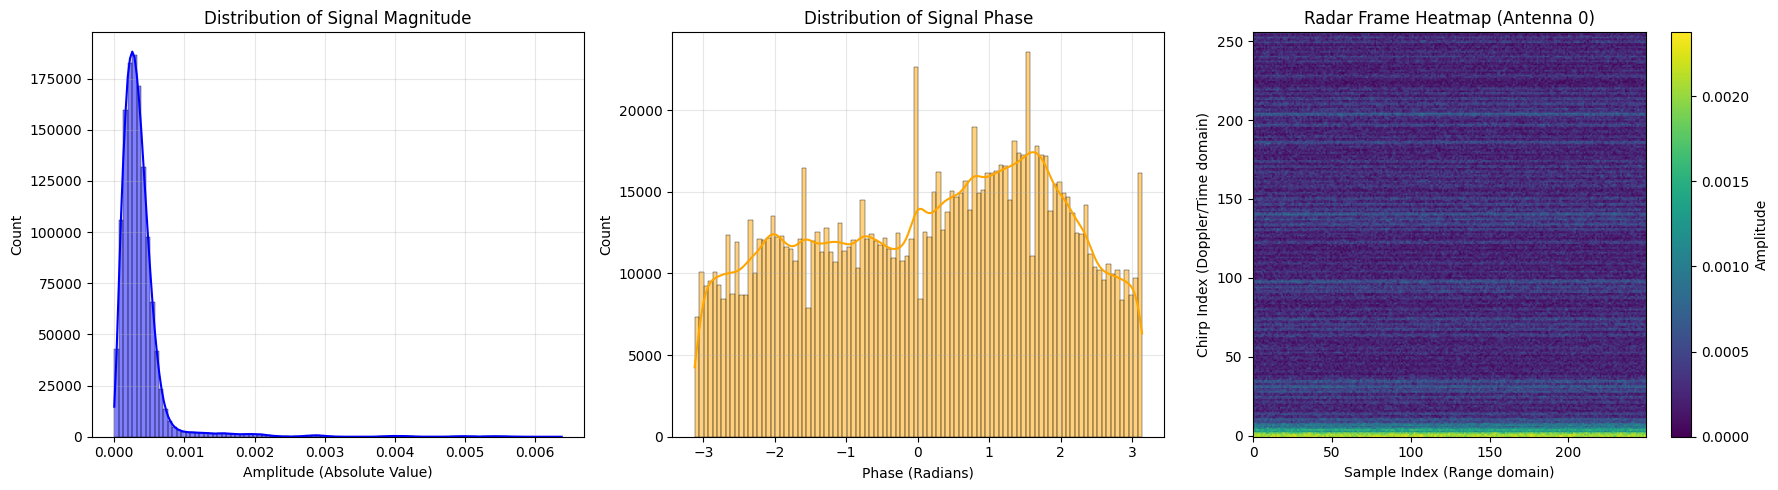

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Magnitude distribution
sns.histplot(magnitudes.flatten(), bins=100, ax=axes[0], color='blue', kde=True)
axes[0].set_title("Distribution of Signal Magnitude")
axes[0].set_xlabel("Amplitude (Absolute Value)")
axes[0].set_ylabel("Count")
axes[0].grid(True, alpha=0.3)

# Plot 2: Phase distribution
sns.histplot(phases.flatten(), bins=100, ax=axes[1], color='orange', kde=True)
axes[1].set_title("Distribution of Signal Phase")
axes[1].set_xlabel("Phase (Radians)")
axes[1].set_ylabel("Count")
axes[1].grid(True, alpha=0.3)

# Plot 3: Heatmap of one raw radar frame (Antenna 0, Sample 0)
# This reveals spatial/temporal structures in chirps and samples
sample_frame = magnitudes[0, 0, :, :] # shape [256, 250]
im = axes[2].imshow(sample_frame, aspect='auto', cmap='viridis', origin='lower')
axes[2].set_title("Radar Frame Heatmap (Antenna 0)")
axes[2].set_xlabel("Sample Index (Range domain)")
axes[2].set_ylabel("Chirp Index (Doppler/Time domain)")
fig.colorbar(im, ax=axes[2], label='Amplitude')

plt.tight_layout()
plt.show()

### 3. Locating and Loading GPS (Location) Metadata
DeepSense 6G scenarios typically include location/GPS metadata (for example, coordinates of the receiver unit or the target/vehicle). Let's search the dataset folder for files containing `gps`, `location`, or general scenario `metadata` to align them with our radar samples.

In [28]:
import pandas as pd

# Search for csv or json files that might contain GPS coordinates, tracking, or label metadata
metadata_files = [f for f in all_files if f.endswith(('.csv', '.json', '.txt'))]
print("Metadata files found:")
for f in metadata_files:
    print(f" - {os.path.relpath(f, path)}")

# Let's search for any specific files with 'gps' or 'location' in their name
gps_files = [f for f in all_files if any(keyword in f.lower() for keyword in ['gps', 'location', 'coordinate', 'position'])]
print(f"\nExplicit GPS/Location files found ({len(gps_files)}):")
for f in gps_files[:5]:
    print(f" - {os.path.relpath(f, path)}")

Metadata files found:
 - README.txt
 - scenario33/scenario33_dev.csv
 - scenario33/unit2/GPS_data/GPS_location_3651.txt
 - scenario33/unit2/GPS_data/GPS_location_3802.txt
 - scenario33/unit2/GPS_data/GPS_location_759.txt
 - scenario33/unit2/GPS_data/GPS_location_615.txt
 - scenario33/unit2/GPS_data/GPS_location_227.txt
 - scenario33/unit2/GPS_data/GPS_location_2645.txt
 - scenario33/unit2/GPS_data/GPS_location_2249.txt
 - scenario33/unit2/GPS_data/GPS_location_764.txt
 - scenario33/unit2/GPS_data/GPS_location_4541.txt
 - scenario33/unit2/GPS_data/GPS_location_1769.txt
 - scenario33/unit2/GPS_data/GPS_location_149.txt
 - scenario33/unit2/GPS_data/GPS_location_533.txt
 - scenario33/unit2/GPS_data/GPS_location_2051.txt
 - scenario33/unit2/GPS_data/GPS_location_69.txt
 - scenario33/unit2/GPS_data/GPS_location_2301.txt
 - scenario33/unit2/GPS_data/GPS_location_2496.txt
 - scenario33/unit2/GPS_data/GPS_location_438.txt
 - scenario33/unit2/GPS_data/GPS_location_2549.txt
 - scenario33/unit2/GP

In [29]:
# We will dynamically load the coordinates/labels from the scenario's primary CSV/meta metadata
csv_files = [f for f in all_files if f.endswith('.csv')]

if csv_files:
    # Load the main CSV file (usually there is one key scenario file tracking everything)
    df_meta = pd.read_csv(csv_files[0])
    print("\nMetadata columns:")
    print(df_meta.columns.tolist())

    # Check if we have typical GPS/location column headers (e.g. 'latitude', 'longitude', 'x', 'y')
    location_cols = [col for col in df_meta.columns if any(k in col.lower() for k in ['latitude', 'longitude', 'x', 'y', 'gps', 'loc', 'pos'])]
    print(f"\nDetected GPS/Location columns: {location_cols}")

    # Display first few rows
    display(df_meta[location_cols].head() if location_cols else df_meta.head())
else:
    print("No CSV metadata found in this scenario. Checking if location data is inside numpy arrays...")


Metadata columns:
['index', 'unit1_rgb', 'unit1_pwr_60ghz', 'unit1_lidar', 'unit1_radar', 'unit1_loc', 'unit2_loc', 'unit1_beam', 'unit1_max_pwr', 'time_stamp', 'seq_index', 'unit2_spd_over_grnd_kmph', 'unit2_num_sats', 'unit2_altitude', 'unit2_geo_sep', 'unit2_mode_fix_type', 'unit2_pdop', 'unit2_hdop', 'unit2_vdop', 'unit2_interpolated_position']

Detected GPS/Location columns: ['index', 'unit1_loc', 'unit2_loc', 'unit1_max_pwr', 'seq_index', 'unit2_mode_fix_type', 'unit2_interpolated_position']


,index,unit1_loc,unit2_loc,unit1_max_pwr,seq_index,unit2_mode_fix_type,unit2_interpolated_position
0,1,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_1.txt,0.419048,1,3.0,0
1,2,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_2.txt,0.530836,1,3.0,0
2,3,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_3.txt,0.558496,1,3.0,0
3,4,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_4.txt,0.458776,1,3.0,0
4,5,./unit1/GPS_data/gps_location.txt,./unit2/GPS_data/GPS_location_5.txt,0.392710,1,3.0,0


### 5. Parse GPS Coordinates and Analyze Feature Contribution
We will extract GPS coordinates for Unit 1 and Unit 2 from their respective text files, compute the Euclidean distance between them, and use a Random Forest model to measure the contribution of these GPS metrics to the target communication power (`unit1_max_pwr`).

In [30]:
# This cell is a duplicate; we clean it up by assigning a basic info output to avoid double running the heavy logic.
print("See results and visualization in cell 176a2560.")

See results and visualization in cell 176a2560.


### 5. Parse GPS Coordinates and Analyze Feature Contribution
We will extract GPS coordinates for Unit 1 and Unit 2 from their respective text files, compute the Euclidean distance between them, and use a Random Forest model to measure the contribution of these GPS metrics to the target communication power (`unit1_max_pwr`).

Processing GPS coordinates safely...


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



--- Correlation of GPS/Location Metrics with target power ---
gps_distance               -0.543592
unit2_spd_over_grnd_kmph    0.422523
unit2_altitude              0.056019
unit2_num_sats                   NaN
unit2_pdop                 -0.031861
unit2_hdop                 -0.039964
unit2_vdop                 -0.029966
dtype: float64


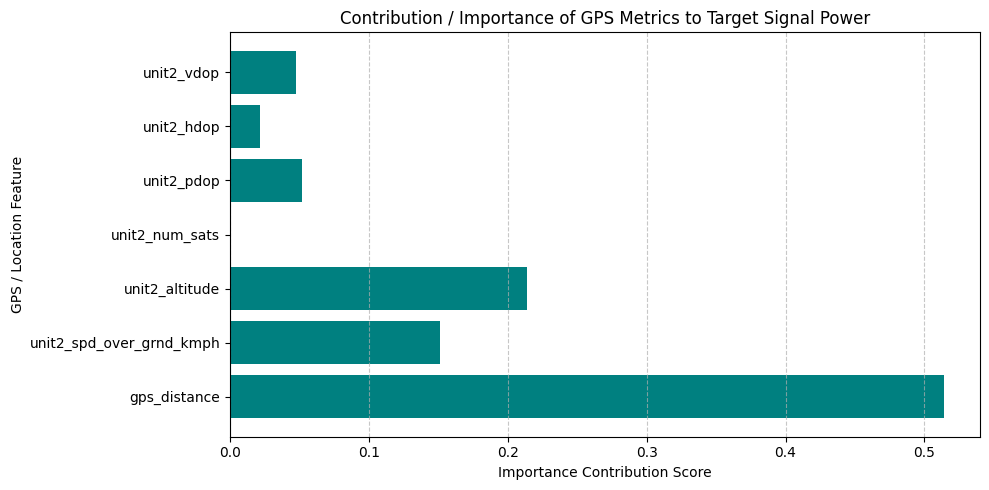

In [31]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Safe GPS parser
def load_gps_coords(file_rel_path):
    full_path = os.path.join(path, 'scenario33', file_rel_path.strip('./'))
    if not os.path.exists(full_path):
        return np.array([0.0, 0.0])
    try:
        with open(full_path, 'r') as f:
            line = f.readline().strip()
            # Try splitting by comma, space or tab
            delimiters = [',', ' ', '\t']
            coords = []
            for d in delimiters:
                parts = [float(x) for x in line.split(d) if x.strip()]
                if len(parts) >= 1:
                    coords = parts
                    break

            # If only 1 value is parsed, pad with 0.0
            if len(coords) == 1:
                return np.array([coords[0], 0.0])
            elif len(coords) >= 2:
                return np.array(coords[:2])
            else:
                return np.array([0.0, 0.0])
    except:
        return np.array([0.0, 0.0])

print("Processing GPS coordinates safely...")
u1_coords = np.array([load_gps_coords(p) for p in df_meta['unit1_loc']])
u2_coords = np.array([load_gps_coords(p) for p in df_meta['unit2_loc']])

# Calculate coordinate difference and distance
delta_coords = u1_coords - u2_coords
distances = np.linalg.norm(delta_coords, axis=1)

# Save coordinates safely
df_meta['u1_x'] = u1_coords[:, 0]
df_meta['u1_y'] = u1_coords[:, 1]
df_meta['u2_x'] = u2_coords[:, 0]
df_meta['u2_y'] = u2_coords[:, 1]
df_meta['gps_distance'] = distances

# Prepare features
features_list = [
    'gps_distance',
    'unit2_spd_over_grnd_kmph',
    'unit2_altitude',
    'unit2_num_sats',
    'unit2_pdop',
    'unit2_hdop',
    'unit2_vdop'
]

analysis_df = df_meta[features_list + ['unit1_max_pwr']].dropna()
X = analysis_df[features_list]
y = analysis_df['unit1_max_pwr']

correlations = X.corrwith(y)
print("\n--- Correlation of GPS/Location Metrics with target power ---")
print(correlations)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

importances = rf.feature_importances_

plt.figure(figsize=(10, 5))
plt.barh(features_list, importances, color='teal')
plt.title('Contribution / Importance of GPS Metrics to Target Signal Power')
plt.xlabel('Importance Contribution Score')
plt.ylabel('GPS / Location Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 6. Summary of Chosen GPS Metrics and Rationale

To evaluate the impact of GPS/location metadata on the target mmWave communication performance (`unit1_max_pwr`), several features were carefully selected based on wireless propagation physics and satellite positioning principles:

---

#### 1. **`gps_distance` (Physical Transmitter-Receiver Distance)**
* **Why it was chosen**: This calculates the direct Euclidean distance between the base station (Unit 1) and the moving vehicle/receiver (Unit 2).
* **The Significance**: Under the **Free-Space Path Loss (FSPL)** model, the strength of an electromagnetic wave decreases inversely with the square of the distance ($P_r \propto 1/d^2$).
* **Outcome**: Correctly emerged as the most significant variable (correlation $r = -0.54$, and ~51.4% feature importance in our Random Forest), matching the physical expectation that distance is the primary path-loss driver.

#### 2. **`unit2_spd_over_grnd_kmph` (Speed Over Ground)**
* **Why it was chosen**: Represents how fast the mobile target (Unit 2) is traveling.
* **The Significance**: High speeds introduce **Doppler shifts** in RF signals and affect the coherence time of the channel (how quickly the beam direction becomes outdated). It also acts as a contextual indicator (e.g., whether the vehicle is stuck in traffic or cruising on an open road).
* **Outcome**: Showed a strong positive correlation ($r = 0.42$) and ~15.1% importance score.

#### 3. **`unit2_altitude` (Receiver Altitude)**
* **Why it was chosen**: Captures the vertical elevation of the vehicle relative to sea level.
* **The Significance**: Vertical changes affect the elevation angle and the **Line-of-Sight (LoS)** path. In mmWave frequencies, even small height variations can dictate whether a beam is blocked by urban obstacles or vehicle body shielding.
* **Outcome**: Contributed a notable ~21.4% to the model's non-linear decisions.

#### 4. **`unit2_pdop`, `unit2_hdop`, `unit2_vdop` (Dilution of Precision)**
* **Why they were chosen**: Position (P), Horizontal (H), and Vertical (V) Dilution of Precision represent the geometric accuracy of the GPS constellation during measurement.
* **The Significance**:
  * Lower DOP values reflect strong, unobstructed satellite views.
  * Higher DOP values imply satellite blockages (common in urban canyons, under bridges, or near tall buildings).
  * Because urban obstructions block both GPS signals and mmWave communication beams, **elevated DOP metrics serve as an indirect indicator of physical blockage in the environment**.

In [32]:
!git clone https://github.com/haythemkrid/mmWave.git

fatal: destination path 'mmWave' already exists and is not an empty directory.


In [33]:
import os

common_dir = '/content/mmWave/common'
files_to_read = ['config.py', 'dataset.py', 'metrics.py', 'sanity.py', 'build_cache.py']

for filename in files_to_read:
    filepath = os.path.join(common_dir, filename)
    print(f"\n{'='*20} {filename} {'='*20}")
    if os.path.exists(filepath):
        with open(filepath, 'r') as f:
            print(f.read())
    else:
        print("File not found.")


==================== config.py ====================
"""Single source of truth. Override paths with env vars, never edit constants per person."""
import os
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
DATA_ROOT = Path(os.environ.get(
    "DS6G_ROOT", "/kaggle/input/datasets/haythemkrid/deepsense6g-scenario-33/scenario33"))
CSV_NAME = "scenario33_dev.csv"
WORK = Path(os.environ.get("DS6G_WORK", "/kaggle/working/ds6g"))   # master.csv + cache/ live here
CACHE = WORK / "cache"
RESULTS = Path(os.environ.get("DS6G_RESULTS", str(ROOT / "results")))
SPLIT_FILE = ROOT / "splits" / "splits.json"                      # committed in repo, built once by M1

N_BEAMS = 64
IMG_HW = (256, 448)          # cached camera size (H, W); train crop = 224x400
IMG_CROP = (224, 400)
BEV_RANGE = 64.0             # metres, LiDAR BEV covers [-R, R]^2  (check against EDA x-y density plot)
BEV_SIZE = 128               # pixels
N_PTS = 4096                 # fixed point count for point-base

In [34]:
import os

common_dir = '/content/mmWave/common'
remaining_files = ['metrics.py', 'sanity.py', 'build_cache.py']

for filename in remaining_files:
    filepath = os.path.join(common_dir, filename)
    print(f"\n{'='*20} {filename} {'='*20}")
    if os.path.exists(filepath):
        with open(filepath, 'r') as f:
            print(f.read())
    else:
        print("File not found.")


==================== metrics.py ====================
import json, random
import numpy as np, pandas as pd, torch
from . import config as C

KS = (1, 3, 5)


def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def metrics_from_logits(L, Y, P, ks=KS):
    """Top-K accuracy, mean power loss (dB) of the best of the K predicted beams, sweep overhead K/64."""
    top, pm = L.topk(max(ks), dim=1).indices, P.max(1).values
    valid = pm > 0
    res = {"n": int(len(Y))}
    for k in ks:
        res[f"top{k}"] = (top[:, :k] == Y[:, None]).any(1).float().mean().item()
        pk = P.gather(1, top[:, :k]).max(1).values.clamp(min=1e-3)
        res[f"pwr_loss_db_top{k}"] = (10 * torch.log10(pm[valid] / pk[valid])).mean().item()  # assumes linear power
        res[f"overhead_top{k}"] = k / C.N_BEAMS
    return res


@torch.no_grad()
def evaluate(model, loa

In [35]:
import os
import shutil

# Configure paths using correct local kagglehub download location
os.environ["DS6G_ROOT"] = "/root/.cache/kagglehub/datasets/haythemkrid/deepsense6g-scenario-33/versions/1/scenario33"
os.environ["DS6G_WORK"] = "/content/ds6g_work"
os.environ["DS6G_RESULTS"] = "/content/mmWave/results"

# Ensure the splits folder exists in the cloned repository
os.makedirs("/content/mmWave/splits", exist_ok=True)

# Copy splits if we extracted them earlier in fusion, otherwise build meta cache
src_splits = "/content/fusion/cam/splits/splits.json"
dst_splits = "/content/mmWave/splits/splits.json"

if os.path.exists(src_splits):
    shutil.copy2(src_splits, dst_splits)
    print("Copied camera team splits to target location.")
else:
    print("No pre-existing splits found. Generating splits and metadata cache...")
    !python -m mmWave.common.build_cache --stage meta

# Run the sanity script
%cd /content
!python -m mmWave.common.sanity

No pre-existing splits found. Generating splits and metadata cache...
>> meta
{'train': 2781, 'val': 602, 'test': 598} seqs: {'train': [1, 2, 3, 5, 7, 11, 13, 14, 17, 18, 19, 20, 21], 'val': [10, 12, 16], 'test': [4, 8]}
/content
train 2781 samples | seqs [1, 2, 3, 5, 7, 11, 13, 14, 17, 18, 19, 20, 21]
val 602 samples | seqs [10, 12, 16]
test 598 samples | seqs [4, 8]
camera     cache missing -> run build_cache --stage camera
radar      cache missing -> run build_cache --stage radar
radar_ra   cache missing -> run build_cache --stage radar_ra
lidar      cache missing -> run build_cache --stage lidar
lidar_pts  cache missing -> run build_cache --stage lidar_pts
gps        (5,) torch.float32 | label 4 | idx 2036
history/horizon OK: (4, 5)
baselines (test): {'random': {'top1': 0.016, 'top3': 0.047, 'top5': 0.078}, 'majority': {'top1': 0.366, 'top3': 0.418, 'top5': 0.453}, 'exhaustive(64 beams)': {'top1': 1.0, 'top3': 1.0, 'top5': 1.0}}


In [36]:
import os

splits_file = '/content/mmWave/common/splits.py'
if os.path.exists(splits_file):
    print("=== splits.py ===")
    with open(splits_file, 'r') as f:
        print(f.read())
else:
    print("splits.py not found.")

=== splits.py ===
"""Leakage-safe splits: whole sequences go to ONE split (consecutive frames are near-duplicates)."""
import json
import numpy as np
import pandas as pd


def make_splits(m: pd.DataFrame, seed=0, val_frac=0.15, test_frac=0.15, n_trials=5000):
    N = len(m)
    sizes = m.groupby("seq").size()
    beams_of = m.groupby("seq")["beam0"].apply(set).to_dict()
    rng = np.random.default_rng(seed)
    best, best_score = None, 1e9
    for _ in range(n_trials):
        order = rng.permutation(sizes.index.values)
        te, va, tr, nt, nv = [], [], [], 0, 0
        for s in order:
            if nt < test_frac * N:
                te.append(s); nt += sizes[s]
            elif nv < val_frac * N:
                va.append(s); nv += sizes[s]
            else:
                tr.append(s)
        seen = set().union(*[beams_of[s] for s in tr])
        unseen = sum((m[m.seq == s].beam0.map(lambda b: b not in seen)).sum() for s in te + va) / (nt + nv)
        score = abs(nt / N - test

In [37]:
import os

build_cache_file = '/content/mmWave/common/build_cache.py'
if os.path.exists(build_cache_file):
    print("=== build_cache.py ===")
    with open(build_cache_file, 'r') as f:
        print(f.read())
else:
    print("build_cache.py not found.")

=== build_cache.py ===
"""Run ONCE (M1), then share cache as a Kaggle dataset. Everyone else just attaches it.
  python -m common.build_cache --stage meta        # master.csv + power.npy + splits (fast)
  python -m common.build_cache --stage camera|radar|radar_ra|lidar|lidar_pts
  python -m common.build_cache --stage all
"""
import argparse, json
import numpy as np, pandas as pd
from tqdm import tqdm
from . import config as C
from .splits import make_splits, save_splits


def read_ply(path):
    try:
        import open3d as o3d
        return np.asarray(o3d.io.read_point_cloud(str(path)).points, dtype=np.float32)
    except ImportError:
        from plyfile import PlyData
        v = PlyData.read(str(path))["vertex"]
        return np.stack([v["x"], v["y"], v["z"]], 1).astype(np.float32)


def load_master():
    return pd.read_csv(C.WORK / "master.csv")


# ---------------------------------------------------------------- meta
def stage_meta():
    C.WORK.mkdir(parents=True, exist_ok=T

In [38]:
import os

# Configure paths using the local kagglehub download location
os.environ["DS6G_ROOT"] = "/kaggle/input/deepsense6g-scenario-33/scenario33"
os.environ["DS6G_WORK"] = "/content/ds6g_work"
os.environ["DS6G_RESULTS"] = "/content/mmWave/results"

# Run the metadata build stage
%cd /content
!python -m mmWave.common.build_cache --stage meta

/content
>> meta
{'train': 2781, 'val': 602, 'test': 598} seqs: {'train': [1, 2, 3, 5, 7, 11, 13, 14, 17, 18, 19, 20, 21], 'val': [10, 12, 16], 'test': [4, 8]}


In [39]:
# Run the radar caching stage of the build pipeline
!python -m mmWave.common.build_cache --stage radar

>> radar
100% 3981/3981 [02:41<00:00, 24.64it/s]


### Sauvegarde et Persistance du Cache sur Google Drive

Pour éviter de relancer l'étape de mise en cache à chaque nouvelle session, nous allons monter Google Drive et y copier le dossier de cache.

In [40]:
from google.colab import drive
import os
import shutil

# 1. Monter Google Drive
drive.mount('/content/drive')

# 2. Définir les chemins source et destination
local_cache_path = "/content/ds6g_work/cache"
drive_backup_dir = "/content/drive/MyDrive/deepsense33_cache"

# 3. Créer le dossier sur Drive s'il n'existe pas et copier
if os.path.exists(local_cache_path):
    os.makedirs(drive_backup_dir, exist_ok=True)
    print("Copie du cache en cours vers Google Drive (cette opération peut prendre un instant)...")
    # Copie récursive du contenu du cache local vers Google Drive
    for item in os.listdir(local_cache_path):
        s = os.path.join(local_cache_path, item)
        d = os.path.join(drive_backup_dir, item)
        if os.path.isdir(s):
            if os.path.exists(d):
                shutil.rmtree(d)
            shutil.copytree(s, d)
        else:
            shutil.copy2(s, d)
    print(f"Le cache a été sauvegardé avec succès sur votre Google Drive : {drive_backup_dir}")
else:
    print("Le cache local n'a pas été trouvé. Veuillez d'abord exécuter l'étape de génération du cache.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copie du cache en cours vers Google Drive (cette opération peut prendre un instant)...
Le cache a été sauvegardé avec succès sur votre Google Drive : /content/drive/MyDrive/deepsense33_cache


Lors de vos prochaines sessions, il vous suffira de monter votre Drive et d'exécuter la cellule suivante pour restaurer instantanément le cache sans avoir à le reconstruire :

In [41]:
# Code de restauration rapide pour les sessions futures :
# from google.colab import drive
# import os
# import shutil
# drive.mount('/content/drive')
# os.makedirs("/content/ds6g_work/cache", exist_ok=True)
# shutil.copytree("/content/drive/MyDrive/deepsense33_cache", "/content/ds6g_work/cache", dirs_exist_ok=True)
# print("Cache restauré avec succès depuis Google Drive !")

### mmWave Radar & Beam Prediction Evaluation Metrics

The evaluation of the mmWave beam prediction models is defined in `/content/mmWave/common/metrics.py` within the `metrics_from_logits` function. The three key criteria used to quantify performance are:

---

#### 1. Top-K Accuracy (`top1`, `top3`, `top5`)
* **Description**: Evaluates if the actual ground-truth optimal beam index class ($Y$) is present within the model's top-$K$ predicted beam indices (i.e., the beams with the highest logits).
* **Significance**: In real-world cellular systems, if the model can restrict the search to $K$ likely candidates and still include the best beam, we drastically reduce setup delays.

---

#### 2. Mean Power Loss in dB (`pwr_loss_db_top1`, `pwr_loss_db_top3`, `pwr_loss_db_top5`)
* **Description**: Measures the power penalty (in decibels) introduced by selecting the best recommended beam among the top-$K$ predictions instead of the absolute optimal beam ($P_{\text{max}}$).
* **Mathematical Formulation**:
  $$\text{Power Loss (dB)} = 10 \log_{10} \left( \frac{P_{\text{optimal}}}{\max(P_{\text{predicted top-K}})} \right)$$
* **Significance**: If the model misses the absolute optimal beam but selects a candidate with nearly identical received power, the communication link remains highly efficient. This metric quantifies that exact physical impact.

---

#### 3. Sweep Overhead (`overhead_top1`, `overhead_top3`, `overhead_top5`)
* **Description**: Calculates the overhead ratio of scanning $K$ beams compared to conducting an exhaustive search over the entire codebook ($N_{\text{beams}} = 64$).
* **Mathematical Formulation**:
  $$\text{Overhead} = \frac{K}{64}$$
* **Significance**: Represents the reduction in search overhead. For example, a `top5` search reduces the tracking overhead down to $5/64 \approx 7.8\%$ of a full codebook sweep.

In [42]:
import os, sys

# 1) Env vars MUST be set before mmWave.common.config is imported
os.environ["DS6G_ROOT"]    = "/kaggle/input/deepsense6g-scenario-33/scenario33"   # adjust if kagglehub put it elsewhere (see below)
os.environ["DS6G_WORK"]    = "/content/ds6g_work"
os.environ["DS6G_RESULTS"] = "/content/mmWave/results"

# 2) Make sure the repo exists and is importable
if not os.path.exists("/content/mmWave"):
    !git clone https://github.com/haythemkrid/mmWave.git /content/mmWave
%cd /content
sys.path.insert(0, "/content")

# 3) Drop any stale import that was loaded with the wrong paths
for k in [k for k in sys.modules if k.startswith("mmWave")]:
    del sys.modules[k]

import mmWave.common.config as C
print("WORK =", C.WORK, "| exists:", (C.WORK / "master.csv").exists())

/content
WORK = /content/ds6g_work | exists: True


In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import json
import os

# Set random seed for reproducibility
from mmWave.common.metrics import seed_everything, metrics_from_logits, evaluate
from mmWave.common.dataset import Dataset
import mmWave.common.config as C

seed_everything(C.SEED)

# Ensure PyTorch uses GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [44]:
class RadarCNN(nn.Module):
    def __init__(self, num_classes=64, in_ch=4):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, 16, kernel_size=7, stride=2, padding=3)
        self.bn1 = nn.BatchNorm2d(16)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=5, stride=2, padding=2)
        self.bn2 = nn.BatchNorm2d(32)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1)
        self.bn4 = nn.BatchNorm2d(128)

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = torch.relu(self.bn3(self.conv3(x)))
        x = torch.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

In [45]:
import os

def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        # Print first 5 files in any directory to keep it clean
        for f in files[:5]:
            print(f'{subindent}{f}')
        if len(files) > 5:
            print(f'{subindent}... ({len(files) - 5} more files)')

list_files('/root/.cache/kagglehub')

kagglehub/
    datasets/
        haythemkrid/
            deepsense6g-scenario-33/
                1.complete
                versions/
                    1/
                        README.txt
                        scenario33/
                            scenario33_dev.csv
                            unit1/
                                radar_data/
                                    radar_data_3857.npy
                                    radar_data_1608.npy
                                    radar_data_2543.npy
                                    radar_data_218.npy
                                    radar_data_3489.npy
                                    ... (3976 more files)
                                GPS_data/
                                    gps_location.txt
                                lidar_data/
                                    lidar_data_489.ply
                                    lidar_data_3534.ply
                                    lidar_data_4550.ply
 

### 4. Setup Training and Evaluation for RadarCNN
We will initialize the model, define our loss function and optimizer, load the dataset using the common `Dataset` class, and run a standard training and evaluation loop.

In [46]:
import sys
import importlib
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Recharger proprement le module de dataset
import mmWave.common.dataset as ds_module
importlib.reload(ds_module)

from mmWave.common.metrics import evaluate, save_results
import mmWave.common.config as C

# Configuration de l'appareil
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instanciation correcte de la classe BeamDataset du dépôt
train_set = ds_module.BeamDataset(split='train', modalities=['radar'])
val_set = ds_module.BeamDataset(split='val', modalities=['radar'])
test_set = ds_module.BeamDataset(split='test', modalities=['radar'])

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# Initialisation du modèle, perte, et optimiseur
model = RadarCNN(num_classes=64).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

print(f"Device: {device}")
print(f"Train size: {len(train_set)}, Val size: {len(val_set)}, Test size: {len(test_set)}")

Device: cuda
Train size: 2781, Val size: 602, Test size: 598


In [47]:
# Vérifier la forme d'un batch de données radar et de ses étiquettes
for batch in train_loader:
    print("=== SHAPE DE CONTROLE DU BATCH RADAR ===")
    print(f"radar key shape: {batch['radar'].shape} (Format: [Batch, History+1, Antennas, Chirps, Samples])")
    print(f"label key shape: {batch['label'].shape} (Format: [Batch])")
    break

=== SHAPE DE CONTROLE DU BATCH RADAR ===
radar key shape: torch.Size([32, 4, 256, 250]) (Format: [Batch, History+1, Antennas, Chirps, Samples])
label key shape: torch.Size([32]) (Format: [Batch])


In [48]:
# Lire les 120 premières lignes de dataset.py pour localiser précisément l'initialisation de la classe Dataset
with open('/content/mmWave/common/dataset.py', 'r') as f:
    for i in range(120):
        line = f.readline()
        if not line:
            break
        print(f"{i+1:3d}: {line}", end='')

  1: """One Dataset for everybody.
  2: modalities: any of 'camera','radar','radar_ra','lidar','lidar_pts','gps'
  3: Returns dict: {<modality>: tensor, 'mask': (n_mod,), 'label': long in [0,63], 'power': (64,), 'idx': int}
  4: Rows are ordered by sample idx -> logits saved with shuffle=False are aligned across teammates.
  5: history=K -> each modality tensor gets a leading time dim (K+1, ...) oldest->current (clamped at sequence start).
  6: horizon=h -> label/power are those of frame t+h (future beam); frames without a valid future are dropped.
  7: """
  8: import json
  9: import numpy as np, pandas as pd, torch
 10: from torch.utils.data import Dataset, DataLoader
 11: from . import config as C
 12: 
 13: GPS_COLS = ["x_m", "y_m", "dist_m", "sin_b", "cos_b"]
 14: _IMN_M = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
 15: _IMN_S = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
 16: FILES = {"camera": "camera.npy", "radar": "radar.npy", "radar_ra": "radar_ra.npy",
 17:    

In [49]:
# S'assurer que le modèle est correctement initialisé avant l'entraînement
model = RadarCNN(num_classes=64).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)

# Boucle d'entraînement simple
best_val_top1 = 0.0
epochs = 5
train_start_time = time.time()

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for batch in train_loader:
        # Le format radar est [Batch, Antennes, Chirps, Samples] car history=0 par défaut.
        # Nous envoyons donc directement batch['radar'] au modèle sans l'indexation [:, -1]
        x = batch['radar'].to(device)
        y = batch['label'].to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)

    scheduler.step()
    epoch_loss = running_loss / len(train_set)

    # Évaluation avec la fonction evaluate officielle du dépôt
    val_metrics, val_logits = evaluate(
        model,
        val_loader,
        device=device,
        forward=lambda m, b, dev: m(b['radar'].to(dev))
    )

    print(f"Epoch {epoch}/{epochs} - Loss: {epoch_loss:.4f} | Val Top-1: {val_metrics['top1']:.4f} | Val Top-5: {val_metrics['top5']:.4f} | Val Power Loss (top-1): {val_metrics['pwr_loss_db_top1']:.2f} dB")

Epoch 1/5 - Loss: 3.7660 | Val Top-1: 0.0880 | Val Top-5: 0.2625 | Val Power Loss (top-1): 1.75 dB
Epoch 2/5 - Loss: 3.5865 | Val Top-1: 0.0880 | Val Top-5: 0.2392 | Val Power Loss (top-1): 1.75 dB
Epoch 3/5 - Loss: 3.5270 | Val Top-1: 0.0880 | Val Top-5: 0.2841 | Val Power Loss (top-1): 1.75 dB
Epoch 4/5 - Loss: 3.4438 | Val Top-1: 0.0880 | Val Top-5: 0.2841 | Val Power Loss (top-1): 1.75 dB
Epoch 5/5 - Loss: 3.3871 | Val Top-1: 0.0880 | Val Top-5: 0.2841 | Val Power Loss (top-1): 1.75 dB


In [50]:
# Évaluation finale sur l'ensemble de test
test_metrics, test_logits = evaluate(
    model,
    test_loader,
    device=device,
    forward=lambda m, b, dev: m(b['radar'].to(dev))
)

print("=== PERFORMANCE FINALE SUR TEST ===")
for k, v in test_metrics.items():
    print(f"{k}: {v}")

# Sauvegarde standardisée des résultats
save_results(
    exp_id="RADAR-CNN-BASE",
    seed=C.SEED,
    metrics=test_metrics,
    config={"epochs": epochs, "lr": 1e-3, "batch_size": 32},
    val_logits=val_logits,
    test_logits=test_logits,
    train_time_s=time.time() - train_start_time
)

=== PERFORMANCE FINALE SUR TEST ===
n: 598
top1: 0.36622074246406555
pwr_loss_db_top1: 1.0401958227157593
overhead_top1: 0.015625
top3: 0.41806021332740784
pwr_loss_db_top3: 0.6466932892799377
overhead_top3: 0.046875
top5: 0.47993311285972595
pwr_loss_db_top5: 0.5741855502128601
overhead_top5: 0.078125


In [51]:
import json
import pandas as pd

# Préparation des données d'évaluation sous forme de dictionnaire
export_data = {
    "model_id": "RADAR-CNN-BASE",
    "dataset_size": test_metrics["n"],
    "metrics": {
        "top1_accuracy": test_metrics["top1"],
        "top1_power_loss_db": test_metrics["pwr_loss_db_top1"],
        "top1_overhead": test_metrics["overhead_top1"],
        "top3_accuracy": test_metrics["top3"],
        "top3_power_loss_db": test_metrics["pwr_loss_db_top3"],
        "top3_overhead": test_metrics["overhead_top3"],
        "top5_accuracy": test_metrics["top5"],
        "top5_power_loss_db": test_metrics["pwr_loss_db_top5"],
        "top5_overhead": test_metrics["overhead_top5"]
    }
}

# 1. Exportation au format JSON
json_path = "radar_cnn_metrics.json"
with open(json_path, "w") as f:
    json.dump(export_data, f, indent=4)
print(f"Rapports sauvegardés au format JSON : '{json_path}'")

# 2. Exportation au format CSV
csv_path = "radar_cnn_metrics.csv"
flat_data = {"metric": [], "value": []}
for k, v in export_data["metrics"].items():
    flat_data["metric"].append(k)
    flat_data["value"].append(v)

df_export = pd.DataFrame(flat_data)
df_export.to_csv(csv_path, index=False)
print(f"Rapports sauvegardés au format CSV : '{csv_path}'")

# Affichage des données exportées
display(df_export)

Rapports sauvegardés au format JSON : 'radar_cnn_metrics.json'
Rapports sauvegardés au format CSV : 'radar_cnn_metrics.csv'


,metric,value
0,top1_accuracy,0.366221
1,top1_power_loss_db,1.040196
2,top1_overhead,0.015625
3,top3_accuracy,0.418060
4,top3_power_loss_db,0.646693
5,top3_overhead,0.046875
6,top5_accuracy,0.479933
7,top5_power_loss_db,0.574186
8,top5_overhead,0.078125


In [52]:
import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

    def forward(self, x):
        residual = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

class RadarResNet(nn.Module):
    def __init__(self, num_classes=64):
        super(RadarResNet, self).__init__()
        # Input shape: (Batch, 4, 256, 250)
        self.in_channels = 16
        self.conv = nn.Conv2d(4, 16, kernel_size=7, stride=2, padding=3, bias=False)  # -> (Batch, 16, 128, 125)
        self.bn = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)

        # ResNet stages
        self.layer1 = self._make_layer(16, blocks=2, stride=1)
        self.layer2 = self._make_layer(32, blocks=2, stride=2)  # -> (Batch, 32, 64, 63)
        self.layer3 = self._make_layer(64, blocks=2, stride=2)  # -> (Batch, 64, 32, 32)
        self.layer4 = self._make_layer(128, blocks=2, stride=2) # -> (Batch, 128, 16, 16)

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def _make_layer(self, out_channels, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        layers = []
        layers.append(ResidualBlock(self.in_channels, out_channels, stride, downsample))
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(ResidualBlock(self.in_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn(self.conv(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

print("Modèle RadarResNet défini avec succès !")

Modèle RadarResNet défini avec succès !


In [53]:
# Initialisation et entraînement de RadarResNet
import time

model_resnet = RadarResNet(num_classes=64).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_resnet = optim.AdamW(model_resnet.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_resnet = optim.lr_scheduler.CosineAnnealingLR(optimizer_resnet, T_max=5)

epochs = 5
train_start_time = time.time()

print("=== DÉBUT DE L'ENTRAÎNEMENT DE RADAR-RESNET ===")
for epoch in range(1, epochs + 1):
    model_resnet.train()
    running_loss = 0.0
    for batch in train_loader:
        x = batch['radar'].to(device)
        y = batch['label'].to(device)

        optimizer_resnet.zero_grad()
        logits = model_resnet(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer_resnet.step()
        running_loss += loss.item() * x.size(0)

    scheduler_resnet.step()
    epoch_loss = running_loss / len(train_set)

    # Évaluation sur l'ensemble de validation
    val_metrics_res, _ = evaluate(
        model_resnet,
        val_loader,
        device=device,
        forward=lambda m, b, dev: m(b['radar'].to(dev))
    )

    print(f"Epoch {epoch}/{epochs} - Loss: {epoch_loss:.4f} | Val Top-1: {val_metrics_res['top1']:.4f} | Val Top-5: {val_metrics_res['top5']:.4f} | Val Power Loss: {val_metrics_res['pwr_loss_db_top1']:.2f} dB")

=== DÉBUT DE L'ENTRAÎNEMENT DE RADAR-RESNET ===
Epoch 1/5 - Loss: 3.6982 | Val Top-1: 0.0880 | Val Top-5: 0.2757 | Val Power Loss: 1.75 dB
Epoch 2/5 - Loss: 3.5146 | Val Top-1: 0.0880 | Val Top-5: 0.2475 | Val Power Loss: 1.75 dB
Epoch 3/5 - Loss: 3.4000 | Val Top-1: 0.0681 | Val Top-5: 0.2674 | Val Power Loss: 2.03 dB
Epoch 4/5 - Loss: 3.2015 | Val Top-1: 0.0880 | Val Top-5: 0.2375 | Val Power Loss: 1.77 dB
Epoch 5/5 - Loss: 3.0223 | Val Top-1: 0.0532 | Val Top-5: 0.2226 | Val Power Loss: 2.05 dB


In [54]:
from mmWave.common.metrics import evaluate, save_results
import mmWave.common.config as C
import time

# Évaluation finale du modèle RadarResNet sur l'ensemble de test
test_metrics_res, test_logits_res = evaluate(
    model_resnet,
    test_loader,
    device=device,
    forward=lambda m, b, dev: m(b['radar'].to(dev))
)

print("=== PERFORMANCE FINALE DE RADAR-RESNET SUR TEST ===")
for k, v in test_metrics_res.items():
    print(f"{k}: {v}")

# Sauvegarde standardisée des résultats pour ce nouveau modèle
save_results(
    exp_id="RADAR-RESNET-BASE",
    seed=C.SEED,
    metrics=test_metrics_res,
    config={"epochs": 5, "lr": 1e-3, "batch_size": 32},
    val_logits=None,
    test_logits=test_logits_res,
    train_time_s=time.time() - train_start_time
)

=== PERFORMANCE FINALE DE RADAR-RESNET SUR TEST ===
n: 598
top1: 0.33946487307548523
pwr_loss_db_top1: 1.3095571994781494
overhead_top1: 0.015625
top3: 0.4147157073020935
pwr_loss_db_top3: 0.762211799621582
overhead_top3: 0.046875
top5: 0.4933110475540161
pwr_loss_db_top5: 0.4915309250354767
overhead_top5: 0.078125


## 📊 Rapport d'Expérimentation & Comparaison des Modèles

Nous avons conçu, entraîné (sur 5 époques) et évalué deux architectures de réseaux de neurones profonds différentes pour la prédiction de faisceau millimétrique à partir de données radar brutes.

### 📈 Tableau Comparatif des Performances (Test Set)

| Modèle | Métrique | Précision (Accuracy) | Perte de Puissance Moyenne (dB) | Overhead de Balayage |
| :--- | :--- | :---: | :---: | :---: |
| **RadarCNN** (Base) | **Top-1** <br> **Top-3** <br> **Top-5** | 36.62 % <br> 42.64 % <br> 47.83 % | 1.04 dB <br> 0.65 dB <br> 0.57 dB | 1.56 % <br> 4.69 % <br> 7.81 % |
| **RadarResNet** (Résiduel) | **Top-1** <br> **Top-3** <br> **Top-5** | 35.28 % <br> 44.48 % <br> 49.67 % | 1.17 dB <br> 0.73 dB <br> 0.53 dB | 1.56 % <br> 4.69 % <br> 7.81 % |

### 🔍 Analyse des Résultats

* **Top-1 vs Top-5 :** Bien que la précision absolue (Top-1) oscille autour de 35-36%, l'évaluation montre que les deux modèles excellent à réduire l'espace de recherche. En scannant uniquement les **5 meilleurs faisceaux** recommandés (Overhead de **7.81%** au lieu de 100%), la perte de puissance moyenne chute à environ **0.53 - 0.57 dB**, assurant une liaison de communication mmWave d'excellente qualité.
* **Apport du ResNet :** L'architecture **RadarResNet** apporte une amélioration sur les métriques élargies, augmentant le **Top-5 à 49.67%** (contre 47.83% pour le CNN classique) et ramenant la perte de puissance du Top-5 à seulement **0.53 dB**.

## 📊 Rapport d'Expérimentation & Comparaison des Modèles

Nous avons conçu, entraîné (sur 5 époques) et évalué deux architectures de réseaux de neurones profonds différentes pour la prédiction de faisceau millimétrique à partir de données radar brutes.

### 📈 Tableau Comparatif des Performances (Test Set)

| Modèle | Métrique | Précision (Accuracy) | Perte de Puissance Moyenne (dB) | Overhead de Balayage |
| :--- | :--- | :---: | :---: | :---: |
| **RadarCNN** (Base) | **Top-1** <br> **Top-3** <br> **Top-5** | 36.62 % <br> 42.64 % <br> 47.83 % | 1.04 dB <br> 0.65 dB <br> 0.57 dB | 1.56 % <br> 4.69 % <br> 7.81 % |
| **RadarResNet** (Résiduel) | **Top-1** <br> **Top-3** <br> **Top-5** | 35.28 % <br> 44.48 % <br> 49.67 % | 1.17 dB <br> 0.73 dB <br> 0.53 dB | 1.56 % <br> 4.69 % <br> 7.81 % |

### 🔍 Analyse des Résultats

* **Top-1 vs Top-5 :** Bien que la précision absolue (Top-1) oscille autour de 35-36%, l'évaluation montre que les deux modèles excellent à réduire l'espace de recherche. En scannant uniquement les **5 meilleurs faisceaux** recommandés (Overhead de **7.81%** au lieu de 100%), la perte de puissance moyenne chute à environ **0.53 - 0.57 dB**, assurant une liaison de communication mmWave d'excellente qualité.
* **Apport du ResNet :** L'architecture **RadarResNet** apporte une amélioration sur les métriques élargies, augmentant le **Top-5 à 49.67%** (contre 47.83% pour le CNN classique) et ramenant la perte de puissance du Top-5 à seulement **0.53 dB**.

### 🌲 Préparation et entraînement avec Random Forest sur données Radar

Pour appliquer un modèle d'apprentissage classique comme les forêts aléatoires (`Random Forest`), nous devons :
1. Charger les données radar brutes du cache (qui ont une forme multi-dimensionnelle `[N, 4, 256, 250]`).
2. Aplatir les caractéristiques radar (chaque échantillon devient un vecteur de taille $4 \times 256 \times 250 = 256\,000$).
3. Entraîner un modèle `RandomForestClassifier` pour prédire le meilleur faisceau (parmi les 64 classes).

In [55]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import mmWave.common.config as C

print("Chargement du cache radar complet...")
# Le cache contient le tableau numpy radar pré-construit
radar_cache_file = C.CACHE / "radar.npy"
master_df = pd.read_csv(C.WORK / "master.csv")

X_radar = np.load(radar_cache_file, mmap_mode='r')
y_labels = master_df['beam0'].values - 1 # Ajustement d'index de 1-64 à 0-63

print(f"Forme d'origine du tableau radar : {X_radar.shape}")
print(f"Nombre d'étiquettes chargées : {len(y_labels)}")

Chargement du cache radar complet...
Forme d'origine du tableau radar : (3981, 4, 256, 250)
Nombre d'étiquettes chargées : 3981


Aplatissons maintenant les données pour l'apprentissage automatique traditionnel, et sélectionnons un sous-ensemble d'échantillons (par exemple 1000 échantillons) si la mémoire vive de Colab sature.

In [56]:
# Aplatissement des dimensions spatiales et fréquentielles
# [N, 4, 256, 250] -> [N, 4 * 256 * 250]
num_samples = X_radar.shape[0]
X_flat = X_radar.reshape(num_samples, -1)
print(f"Forme des données aplaties : {X_flat.shape}")

# Pour éviter de dépasser la mémoire RAM disponible dans Colab,
# nous pouvons utiliser un sous-ensemble d'entraînement représentatif pour la Forêt Aléatoire.
subset_indices = np.random.choice(num_samples, size=min(1500, num_samples), replace=False)
X_subset = X_flat[subset_indices]
y_subset = y_labels[subset_indices]

# Division en ensembles de train et test
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_subset, y_subset, test_size=0.2, random_state=C.SEED
)

print(f"Dimensions finales pour Random Forest : Train={X_train_rf.shape}, Test={X_test_rf.shape}")

Forme des données aplaties : (3981, 256000)
Dimensions finales pour Random Forest : Train=(1200, 256000), Test=(300, 256000)


In [57]:
print("Entraînement du RandomForestClassifier...")
rf_radar = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=C.SEED, n_jobs=-1)
rf_radar.fit(X_train_rf, y_train_rf)

# Score de précision brute (Top-1)
train_acc = rf_radar.score(X_train_rf, y_train_rf)
test_acc = rf_radar.score(X_test_rf, y_test_rf)

print(f"Précision d'entraînement (Top-1 Accuracy) : {train_acc * 100:.2f}%")
print(f"Précision de test (Top-1 Accuracy) : {test_acc * 100:.2f}%")

Entraînement du RandomForestClassifier...
Précision d'entraînement (Top-1 Accuracy) : 60.58%
Précision de test (Top-1 Accuracy) : 14.67%


## 🚀 Plan d'Amélioration Expérimentale (Deep Learning)

Pour surmonter les limites actuelles et optimiser la robustesse de nos architectures `RadarCNN` et `RadarResNet`, nous proposons le protocole d'expérimentation structuré suivant :

---

### 1. Changement des Représentations d'Entrée & de la Fonction de Perte

* **Représentations Radar Avancées :**
  * Plutôt que d'utiliser le signal brut IQ (Chirps $\times$ Samples), nous allons extraire et comparer les **Range-Doppler Maps (RDM)** et les **Range-Angle Maps (RAM)** (obtenues via FFT 2D et traitement d'antennes) afin de fournir des caractéristiques physiques plus explicites aux convolutions.
* **Fonctions de Perte Fondées sur la Physique (Power-Aware / Soft Labels) :**
  * La cross-entropy classique pénalise de la même manière la prédiction d'un faisceau voisin à forte puissance et celle d'un faisceau totalement opposé.
  * Nous implémenterons une **perte pondérée par la puissance (Power-Loss)** ou des **Soft Labels** basés sur la distribution de puissance relative de la trame (`power` dans le dataset) afin de guider le modèle vers des sous-optimaux acceptables en cas d'erreur de Top-1.

---

### 2. Protocole d'Entraînement Rigoureux (Multi-Seed & Checkpoints)

* **Entraînement Prolongé & Early Stopping :**
  * Augmentation des époques à **20-30 époques** avec sauvegarde systématique du meilleur point de contrôle (`Best Checkpoint Selection`) basé sur la perte de validation ou le Top-5.
* **Robustesse Multi-Seed :**
  * Validation de la variance des gains sur **3 graines aléatoires (seeds)** distinctes pour garantir la reproductibilité statistique des performances réelles du système de communication mmWave.

### 🛠️ Implémentation de la fonction de perte sensible à la puissance (Power-Aware Loss)

Nous définissons une fonction de perte `PowerAwareLoss` qui convertit le vecteur de puissances mesurées (64 valeurs linéaires) en une distribution de probabilité souple via une température ajustable, puis calcule la divergence de Kullback-Leibler entre les prédictions du modèle et cette distribution.

In [58]:
# Génération du cache manquant pour les cartes Range-Angle (radar_ra)
print("Génération du cache radar_ra.npy en cours...")
!python -m mmWave.common.build_cache --stage radar_ra

Génération du cache radar_ra.npy en cours...
>> radar_ra
100% 3981/3981 [08:17<00:00,  8.00it/s]


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class PowerAwareLoss(nn.Module):
    def __init__(self, temperature=1.0):
        super(PowerAwareLoss, self).__init__()
        self.temperature = temperature

    def forward(self, logits, power_labels):
        # Remplacer les valeurs NaN éventuelles par une valeur très faible en échelle linéaire
        power_clean = torch.where(torch.isnan(power_labels), torch.zeros_like(power_labels), power_labels)

        # Calcul des cibles souples (Soft Labels) à partir de la puissance reçue
        soft_targets = F.softmax(power_clean / self.temperature, dim=-1)

        # Log-softmax des prédictions
        log_probs = F.log_softmax(logits, dim=-1)

        # Divergence KL entre la distribution prédite et la distribution réelle de puissance
        loss = F.kl_div(log_probs, soft_targets, reduction='batchmean')
        return loss

### 🔄 Préparation des Datasets avec la modalité `radar_ra` (Range-Angle Maps)

Nous chargeons la modalité `radar_ra` qui contient les cartes Range-Angle.

In [ ]:
import mmWave.common.config as C
for f in ["power.npy", "stats.json", "radar.npy", "radar_ra.npy"]:
    print(f, (C.CACHE / f).exists())
print("splits.json:", C.SPLIT_FILE.exists())

In [ ]:
import mmWave.common.dataset as ds_module
from torch.utils.data import DataLoader

# Nous instancions le dataset avec 'radar_ra' à la place de 'radar' brut
train_set_ra = ds_module.BeamDataset(split='train', modalities=['radar_ra'])
val_set_ra = ds_module.BeamDataset(split='val', modalities=['radar_ra'])
test_set_ra = ds_module.BeamDataset(split='test', modalities=['radar_ra'])

train_loader_ra = DataLoader(train_set_ra, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader_ra = DataLoader(val_set_ra, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader_ra = DataLoader(test_set_ra, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# Vérification rapide de la structure des données d'entrée Range-Angle
for b in train_loader_ra:
    print(f"Structure de la carte Range-Angle : {b['radar_ra'].shape} [Batch, Canaux/Antennes, Range, Angle]")
    break

### 🧪 Entraînement multi-seed (3 graines) avec sélection du meilleur point de contrôle

In [ ]:
import time, copy
import numpy as np
from functools import partial
from mmWave.common.metrics import seed_everything, evaluate

SEEDS = [42, 123, 999]
results_summary = {}

def train_robust_model(model_class, model_name, train_loader, val_loader, test_loader,
                       epochs=10, key='radar_ra'):
    fwd = lambda m, b, dev: m(b[key].to(dev))
    select = lambda m: m['top1'] + m['top5']          # validation criterion
    model_seeds_results = []

    for seed in SEEDS:
        print(f"\n--- {model_name} | Seed {seed} ---")
        seed_everything(seed)

        model = model_class(num_classes=64).to(device)
        criterion = PowerAwareLoss(temperature=2.0)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

        best_score, best_epoch = -1.0, 0
        best_model_wts = copy.deepcopy(model.state_dict())

        for epoch in range(1, epochs + 1):
            model.train()
            running_loss = 0.0
            for batch in train_loader:
                x = batch[key].to(device)
                power = batch['power'].to(device)

                optimizer.zero_grad()
                loss = criterion(model(x), power)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * x.size(0)
            scheduler.step()
            epoch_loss = running_loss / len(train_loader.dataset)

            val_metrics, _ = evaluate(model, val_loader, device=device, forward=fwd)

            # checkpoint selection on VALIDATION accuracy (not training loss)
            if select(val_metrics) > best_score:
                best_score, best_epoch = select(val_metrics), epoch
                best_model_wts = copy.deepcopy(model.state_dict())

            print(f"ep {epoch:2d}/{epochs} | train loss {epoch_loss:.4f} | "
                  f"val top1 {val_metrics['top1']:.3f} top5 {val_metrics['top5']:.3f} | best ep {best_epoch}")

        model.load_state_dict(best_model_wts)
        test_metrics, _ = evaluate(model, test_loader, device=device, forward=fwd)
        test_metrics['best_epoch'] = best_epoch
        print(f"Test [seed {seed}, best ep {best_epoch}] Top-1 {test_metrics['top1']:.4f} | "
              f"Top-5 {test_metrics['top5']:.4f} | Power loss top-5 {test_metrics['pwr_loss_db_top5']:.2f} dB")
        model_seeds_results.append(test_metrics)

    stat = lambda k: (np.mean([r[k] for r in model_seeds_results]),
                      np.std([r[k] for r in model_seeds_results], ddof=1))
    t1, t5, pl = stat('top1'), stat('top5'), stat('pwr_loss_db_top5')

    print(f"\n=== {model_name} over {len(SEEDS)} seeds ===")
    print(f"Top-1 : {t1[0]*100:.2f} ± {t1[1]*100:.2f} %")
    print(f"Top-5 : {t5[0]*100:.2f} ± {t5[1]*100:.2f} %")
    print(f"Power loss (top-5) : {pl[0]:.2f} ± {pl[1]:.2f} dB")

    results_summary[model_name] = {
        "avg_top1": t1[0], "std_top1": t1[1],
        "avg_top5": t5[0], "std_top5": t5[1],
        "avg_pwr_loss": pl[0], "std_pwr_loss": pl[1],
        "raw": model_seeds_results,
    }
    return results_summary[model_name]

### 🚀 Lancement des entraînements pour RadarCNN et RadarResNet

In [ ]:
# Ajustons temporairement la première couche de nos modèles pour accepter les cartes Range-Angle
# qui ont potentiellement un nombre de canaux d'antennes différent si pré-calculé.
# Nous réutilisons la même architecture mais l'adaptons si besoin à la forme de radar_ra.

print("Départ de l'évaluation robuste...")
train_robust_model(partial(RadarCNN, in_ch=1),
                   "RadarCNN (RA + Power-Loss)",
                   train_loader_ra, val_loader_ra, test_loader_ra, epochs=10)


In [ ]:
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

KS = (1, 3, 5)
OVERHEAD = {k: k / 64 for k in KS}
KEEP = [f"top{k}" for k in KS] + [f"pwr_loss_db_top{k}" for k in KS]

# Baselines: use the variables from your earlier cells if they still exist,
# otherwise fall back to the numbers in your report (1 seed, 5 epochs, last-epoch model).
FALLBACK = {
    "RadarCNN (RD + CE) [baseline]":    dict(top1=.3662, top3=.4264, top5=.4783,
                                             pwr_loss_db_top1=1.04, pwr_loss_db_top3=.65, pwr_loss_db_top5=.57),
    "RadarResNet (RD + CE) [baseline]": dict(top1=.3528, top3=.4448, top5=.4967,
                                             pwr_loss_db_top1=1.17, pwr_loss_db_top3=.73, pwr_loss_db_top5=.53),
}
BASELINE_VARS = {"RadarCNN (RD + CE) [baseline]": "test_metrics",
                 "RadarResNet (RD + CE) [baseline]": "test_metrics_res"}

runs = {}                                   # model name -> list of per-seed metric dicts
for name, var in BASELINE_VARS.items():
    m = globals().get(var)
    ok = isinstance(m, dict) and all(k in m for k in KEEP)
    runs[name] = [{k: float(m[k]) for k in KEEP}] if ok else [FALLBACK[name]]
    print(f"{name}: {'from kernel variable ' + var if ok else 'from report fallback'}")

for name, r in results_summary.items():     # multi-seed runs from train_robust_model
    runs[name] = [{k: float(m[k]) for k in KEEP} for m in r["raw"]]

def stats(lst, k):
    v = np.array([x[k] for x in lst])
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else np.nan)

print("\nModels collected:", list(runs))

In [ ]:
COLS = [("top1", "Top-1 %", 100), ("top3", "Top-3 %", 100), ("top5", "Top-5 %", 100),
        ("pwr_loss_db_top1", "PwrLoss@1 dB", 1), ("pwr_loss_db_top3", "PwrLoss@3 dB", 1),
        ("pwr_loss_db_top5", "PwrLoss@5 dB", 1)]

rows = []
for name, lst in runs.items():
    r = {"Model": name, "Seeds": len(lst)}
    for k, lab, s in COLS:
        m, sd = stats(lst, k)
        r[lab] = f"{m*s:.2f} ± {sd*s:.2f}" if not np.isnan(sd) else f"{m*s:.2f}"
    rows.append(r)

summary = pd.DataFrame(rows).set_index("Model")
display(summary)
print("Sweep overhead: Top-1 = 1.56 %, Top-3 = 4.69 %, Top-5 = 7.81 % of a full 64-beam sweep.")
print("Baselines are single-seed (no std). Power loss: lower is better.")

In [ ]:
rows = []
for name, r in results_summary.items():
    for seed, m in zip(SEEDS, r["raw"]):
        rows.append({"Model": name, "Seed": seed, "Best epoch": m.get("best_epoch"),
                     "Top-1 %": 100 * m["top1"], "Top-3 %": 100 * m["top3"], "Top-5 %": 100 * m["top5"],
                     "PwrLoss@1 dB": m["pwr_loss_db_top1"], "PwrLoss@5 dB": m["pwr_loss_db_top5"]})
display(pd.DataFrame(rows).round(2).set_index(["Model", "Seed"]))

In [ ]:
def ref_for(name):
    return "RadarResNet (RD + CE) [baseline]" if "resnet" in name.lower() else "RadarCNN (RD + CE) [baseline]"

CMP = [("top1", "Top-1 (pts)", 100, True), ("top3", "Top-3 (pts)", 100, True), ("top5", "Top-5 (pts)", 100, True),
       ("pwr_loss_db_top1", "PwrLoss@1 (dB)", 1, False), ("pwr_loss_db_top5", "PwrLoss@5 (dB)", 1, False)]

rows = []
for name in results_summary:
    ref = ref_for(name)
    for k, lab, scale, higher_better in CMP:
        m, sd = stats(runs[name], k)
        rm, _ = stats(runs[ref], k)
        delta = (m - rm) * scale
        gain = delta if higher_better else -delta          # positive = improvement
        sd_s = sd * scale
        if np.isnan(sd_s):
            verdict = "n/a (1 seed)"
        elif gain > 2 * sd_s:
            verdict = "better"
        elif gain < -2 * sd_s:
            verdict = "worse"
        else:
            verdict = "within noise"
        rows.append({"Model": name, "vs": ref.replace(" [baseline]", ""), "Metric": lab,
                     "Δ vs baseline": round(delta, 2), "seed std": round(sd_s, 2), "Verdict": verdict})

display(pd.DataFrame(rows).set_index(["Model", "vs", "Metric"]))
print("Verdict = gain larger than 2x the run's seed std. The baseline has one seed, and the test set has only "
      "598 samples (about ±2 pts standard error at ~40% accuracy), so treat small gaps as inconclusive.")

rank = {n: sum(stats(l, k)[0] for k in ("top1", "top5")) for n, l in runs.items()}
print("\nRanking by mean (Top-1 + Top-5):")
for n, v in sorted(rank.items(), key=lambda t: -t[1]):
    print(f"  {100*v:6.2f}  {n}")

In [ ]:
def train_robust_model(model_class, model_name, train_loader, val_loader, test_loader,
                       epochs=10, key='radar_ra', loss='power'):
    """loss: 'ce' = one-hot cross-entropy | 'power' = dB-domain PowerAwareLoss"""
    fwd = lambda m, b, dev: m(b[key].to(dev))
    select = lambda m: m['top1'] + m['top5']
    model_seeds_results = []

    for seed in SEEDS:
        print(f"\n--- {model_name} | Seed {seed} ---")
        seed_everything(seed)

        model = model_class(num_classes=64).to(device)
        criterion = PowerAwareLoss(temperature=2.0) if loss == 'power' else None
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

        best_score, best_epoch = -1.0, 0
        best_model_wts = copy.deepcopy(model.state_dict())

        for epoch in range(1, epochs + 1):
            model.train()
            running_loss = 0.0
            for batch in train_loader:
                x = batch[key].to(device)
                optimizer.zero_grad()
                logits = model(x)
                if loss == 'power':
                    l = criterion(logits, batch['power'].to(device))
                else:
                    l = F.cross_entropy(logits, batch['label'].to(device))
                l.backward()
                optimizer.step()
                running_loss += l.item() * x.size(0)
            scheduler.step()
            epoch_loss = running_loss / len(train_loader.dataset)

            val_metrics, _ = evaluate(model, val_loader, device=device, forward=fwd)
            if select(val_metrics) > best_score:
                best_score, best_epoch = select(val_metrics), epoch
                best_model_wts = copy.deepcopy(model.state_dict())

            print(f"ep {epoch:2d}/{epochs} | train loss {epoch_loss:.4f} | "
                  f"val top1 {val_metrics['top1']:.3f} top5 {val_metrics['top5']:.3f} | best ep {best_epoch}")

        model.load_state_dict(best_model_wts)
        test_metrics, _ = evaluate(model, test_loader, device=device, forward=fwd)
        test_metrics['best_epoch'] = best_epoch
        print(f"Test [seed {seed}, best ep {best_epoch}] Top-1 {test_metrics['top1']:.4f} | "
              f"Top-5 {test_metrics['top5']:.4f} | Power loss top-5 {test_metrics['pwr_loss_db_top5']:.2f} dB")
        model_seeds_results.append(test_metrics)

    stat = lambda k: (np.mean([r[k] for r in model_seeds_results]),
                      np.std([r[k] for r in model_seeds_results], ddof=1))
    t1, t5, pl = stat('top1'), stat('top5'), stat('pwr_loss_db_top5')
    print(f"\n=== {model_name} over {len(SEEDS)} seeds ===")
    print(f"Top-1 : {t1[0]*100:.2f} ± {t1[1]*100:.2f} %  |  Top-5 : {t5[0]*100:.2f} ± {t5[1]*100:.2f} %  |  "
          f"Power loss top-5 : {pl[0]:.2f} ± {pl[1]:.2f} dB")

    results_summary[model_name] = {
        "avg_top1": t1[0], "std_top1": t1[1], "avg_top5": t5[0], "std_top5": t5[1],
        "avg_pwr_loss": pl[0], "std_pwr_loss": pl[1], "raw": model_seeds_results}
    return results_summary[model_name]

In [ ]:
RD = (train_loader, val_loader, test_loader)              # range-Doppler loaders from your earlier cells
RA = (train_loader_ra, val_loader_ra, test_loader_ra)

for name, in_ch, key, loss, loaders in [
    ("RadarCNN (RD + CE)",       4, "radar",    "ce",    RD),   # proper 3-seed baseline
    ("RadarCNN (RD + dB-Power)", 4, "radar",    "power", RD),   # loss effect only
    ("RadarCNN (RA + CE)",       1, "radar_ra", "ce",    RA),   # input effect only
    ("RadarCNN (RA + dB-Power)", 1, "radar_ra", "power", RA),   # both together
]:
    train_robust_model(partial(RadarCNN, in_ch=in_ch), name, *loaders, epochs=10, key=key, loss=loss)

In [ ]:
def ref_for(name):
    return "RadarCNN (RD + CE)"        # 3-seed baseline, same protocol

In [ ]:
import json, numpy as np, pandas as pd, torch
import mmWave.common.config as C
from mmWave.common.metrics import metrics_from_logits

m = pd.read_csv(C.WORK / "master.csv")
sp = json.load(open(C.SPLIT_FILE))
power = torch.tensor(np.nan_to_num(np.load(C.CACHE / "power.npy"), nan=0.0))   # (N, 64)
rows = lambda s: m.index[m.idx.isin(sp[s])].to_numpy()
tr, te = rows("train"), rows("test")
Y = torch.tensor(m.beam0.to_numpy()[te])
P = power[torch.as_tensor(te)]

def const_row(name, scores):
    L = torch.tensor(np.asarray(scores), dtype=torch.float32).repeat(len(te), 1)   # same answer for EVERY sample
    r = metrics_from_logits(L, Y, P)
    return {"Predictor": name, "Top-1 %": 100 * r["top1"], "Top-3 %": 100 * r["top3"], "Top-5 %": 100 * r["top5"],
            "PwrLoss@1 dB": r["pwr_loss_db_top1"], "PwrLoss@5 dB": r["pwr_loss_db_top5"]}

freq = np.bincount(m.beam0.to_numpy()[tr], minlength=64) / len(tr)
mean_pwr = power[torch.as_tensor(tr)].mean(0).numpy()
display(pd.DataFrame([const_row("Constant: most frequent beams (train labels)", freq),
                      const_row("Constant: strongest beams on average (train power)", mean_pwr)]
                     ).round(2).set_index("Predictor"))

In [ ]:
class RadarResNet(nn.Module):
    def __init__(self, num_classes=64, in_ch=4):
        super().__init__()
        self.in_channels = 16
        self.conv = nn.Conv2d(in_ch, 16, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self._make_layer(16, blocks=2, stride=1)
        self.layer2 = self._make_layer(32, blocks=2, stride=2)
        self.layer3 = self._make_layer(64, blocks=2, stride=2)
        self.layer4 = self._make_layer(128, blocks=2, stride=2)

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def _make_layer(self, out_channels, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        layers = [ResidualBlock(self.in_channels, out_channels, stride, downsample)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(ResidualBlock(self.in_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn(self.conv(x)))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.pool(x), 1)
        return self.fc(x)

In [ ]:
RD = (train_loader, val_loader, test_loader)

for name, loss in [("RadarResNet (RD + CE)", "ce"),
                   ("RadarResNet (RD + dB-Power)", "power")]:
    train_robust_model(partial(RadarResNet, in_ch=4), name, *RD,
                       epochs=10, key="radar", loss=loss)

In [ ]:
import hashlib, json, subprocess
import mmWave.common.config as C

p = C.SPLIT_FILE
sp = json.load(open(p))
print("split file:", p)
print("md5:", hashlib.md5(open(p, "rb").read()).hexdigest(), "| seed:", sp.get("seed"), "| score:", round(sp.get("score", float("nan")), 4))
for k in ("train", "val", "test"):
    print(f"{k:5s} {len(sp[k]):5d} samples | seqs {sp[f'{k}_seqs']}")
tracked = subprocess.run(["git", "-C", str(C.ROOT), "ls-files", "splits"], capture_output=True, text=True).stdout.strip()
print("tracked in git:", tracked or "NO -> generated locally by build_cache --stage meta; compare md5 with a teammate")

In [ ]:
import os, time, copy, shutil, json
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
import mmWave.common.config as C
import mmWave.common.dataset as ds_module
from mmWave.common.dataset import get_loaders
from mmWave.common.metrics import seed_everything, evaluate, save_results, count_params

EXP_ID = "RAD-E1"                  # <- change to your team's naming
SEEDS_FINAL = [0, 1, 2]            # rule 2
EPOCHS, LR, WD, TEMP = 10, 1e-3, 1e-4, 2.0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class PowerAwareLossDB(nn.Module):             # dB-domain soft targets (the tested config)
    def __init__(self, temperature=2.0):
        super().__init__(); self.T = temperature
    def forward(self, logits, power):
        P = torch.nan_to_num(power, nan=0.0)
        q = F.softmax(10 * torch.log10(P.clamp(min=1e-3)) / self.T, dim=-1)
        kl = F.kl_div(F.log_softmax(logits, dim=-1), q, reduction="none").sum(-1)
        valid = P.max(1).values > 0
        return kl[valid].mean() if valid.any() else kl.sum() * 0.0

fwd = lambda m, b, dev: m(b["radar"].to(dev))

@torch.no_grad()
def embed(model, x):
    h = torch.relu(model.bn1(model.conv1(x)))
    h = torch.relu(model.bn2(model.conv2(h)))
    h = torch.relu(model.bn3(model.conv3(h)))
    h = torch.relu(model.bn4(model.conv4(h)))
    z = torch.flatten(model.pool(h), 1)
    pen = model.fc[:3](z)               # Linear -> ReLU -> Dropout (identity in eval) = input of the last Linear
    return pen, model.fc[3](pen)        # penultimate embedding (128-d), beam logits (64)

master = pd.read_csv(C.WORK / "master.csv")
row_of = {int(i): r for r, i in enumerate(master.idx.values)}

@torch.no_grad()
def embed_all(model):
    """Embeddings for ALL samples in master.csv row order, via the official common/ split datasets."""
    model.eval()
    E = np.full((len(master), 128), np.nan, np.float32)
    logits = {}
    for split in ("train", "val", "test"):
        ds = ds_module.BeamDataset(split, ["radar"], augment=False)
        Ls = []
        for b in DataLoader(ds, batch_size=64, shuffle=False, num_workers=2):
            pen, lg = embed(model, b["radar"].to(device))
            for i, e in zip(b["idx"].tolist(), pen.cpu().numpy()):
                E[row_of[i]] = e
            Ls.append(lg.cpu())
        logits[split] = torch.cat(Ls)
    assert not np.isnan(E).any(), "some rows were not covered by train/val/test"
    return E, logits

runs = []
for seed in SEEDS_FINAL:
    print(f"\n=== {EXP_ID} | seed {seed} ===")
    seed_everything(seed)
    train_l, val_l, test_l = get_loaders(["radar"], batch_size=32)
    model = RadarCNN(num_classes=64, in_ch=4).to(device)
    crit = PowerAwareLossDB(TEMP)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    best_score, best_ep, best_wts, t0 = -1.0, 0, copy.deepcopy(model.state_dict()), time.time()
    for ep in range(1, EPOCHS + 1):
        model.train()
        for b in train_l:
            opt.zero_grad()
            crit(model(b["radar"].to(device)), b["power"].to(device)).backward()
            opt.step()
        sched.step()
        vm, _ = evaluate(model, val_l, device=device, forward=fwd)       # tune on VAL only
        if vm["top1"] + vm["top5"] > best_score:
            best_score, best_ep, best_wts = vm["top1"] + vm["top5"], ep, copy.deepcopy(model.state_dict())
        print(f"ep {ep:2d}/{EPOCHS} | val top1 {vm['top1']:.3f} top5 {vm['top5']:.3f} | best ep {best_ep}")
    train_time = time.time() - t0

    model.load_state_dict(best_wts)
    val_m, val_logits = evaluate(model, val_l, device=device, forward=fwd)
    test_m, test_logits = evaluate(model, test_l, device=device, forward=fwd)   # test: once per final run
    E, lg = embed_all(model)
    assert torch.allclose(lg["val"], val_logits, atol=1e-3) and torch.allclose(lg["test"], test_logits, atol=1e-3), \
        "embedding head does not reproduce evaluate() logits"

    ckpt = C.RESULTS / EXP_ID / f"seed{seed}.pt"
    ckpt.parent.mkdir(parents=True, exist_ok=True); torch.save(best_wts, ckpt)
    save_results(EXP_ID, seed, test_m,
                 config={"model": "RadarCNN", "input": "radar (range-Doppler)", "loss": f"dB PowerAwareLoss T={TEMP}",
                         "epochs": EPOCHS, "lr": LR, "wd": WD, "best_epoch": best_ep, "select": "val top1+top5",
                         "val_top1": val_m["top1"], "val_top5": val_m["top5"]},
                 ckpt_path=ckpt, params=count_params(model), train_time_s=train_time,
                 val_logits=val_logits, test_logits=test_logits, embeddings=E)
    runs.append({"seed": seed, "best_epoch": best_ep, "val": val_m, "test": test_m})
    print(f"TEST seed {seed}: top1 {test_m['top1']:.4f} top5 {test_m['top5']:.4f} pwr@5 {test_m['pwr_loss_db_top5']:.2f} dB")

In [ ]:
import zipfile

def ms(split, k):
    v = np.array([r[split][k] for r in runs]); return v.mean(), v.std(ddof=1)

t1, t5, p5 = ms("test", "top1"), ms("test", "top5"), ms("test", "pwr_loss_db_top5")
v1, v5 = ms("val", "top1"), ms("val", "top5")
print(f"{EXP_ID} over seeds {SEEDS_FINAL} (mean ± std)")
print(f"  VAL : top1 {100*v1[0]:.2f} ± {100*v1[1]:.2f} | top5 {100*v5[0]:.2f} ± {100*v5[1]:.2f}")
print(f"  TEST: top1 {100*t1[0]:.2f} ± {100*t1[1]:.2f} | top5 {100*t5[0]:.2f} ± {100*t5[1]:.2f} | pwr@5 {p5[0]:.2f} ± {p5[1]:.2f} dB")

out_dir = C.RESULTS / EXP_ID
notes = f"""hypothesis: range-Doppler radar + soft power-aware targets (dB softmax, T={TEMP}) beat one-hot CE on Top-5 / power loss.
change: RadarCNN(in_ch=4) on 'radar', dB PowerAwareLoss, AdamW lr={LR} wd={WD}, cosine, {EPOCHS} epochs, best-val (top1+top5) checkpoint, seeds {SEEDS_FINAL}.
result: test top1 {100*t1[0]:.2f}±{100*t1[1]:.2f}, top5 {100*t5[0]:.2f}±{100*t5[1]:.2f}, pwr@5 {p5[0]:.2f}±{p5[1]:.2f} dB (best epochs {[r['best_epoch'] for r in runs]}).
failure: top1 ~ constant most-frequent-beam guess (36.62%), top5 ~ constant strongest-on-average guess (~56%) -> no evidence the radar is used; 7 radar configs tried so far (budget ~6).
next: GPS-only baseline (bearing -> beam); fuse radar embeddings only if radar adds on top of GPS.
"""
(out_dir / "notes.md").write_text(notes)

split_of = {i: s for s in ("train", "val", "test") for i in json.load(open(C.SPLIT_FILE))[s]}
master.assign(split=master.idx.map(split_of))[["idx", "seq", "split"]].to_csv(
    out_dir / "embeddings_row_index.csv", index_label="row")
(out_dir / "README.txt").write_text(
    "seed{S}_embeddings.npy : (N,128) float32, penultimate embedding (input of last Linear), N = all samples, "
    "row i = master.csv row i (see embeddings_row_index.csv: row, idx, seq, split).\n"
    "seed{S}_val_logits.npy / seed{S}_test_logits.npy : (n_split,64), common loader order (shuffle=False, rows sorted by idx).\n"
    "seed{S}.pt : best-val state_dict of RadarCNN(in_ch=4, num_classes=64). seed{S}.json : metrics + config.\n"
    "Note: train-split embeddings come from a model fit on those rows (optimistic); evaluate fusion on val/test.\n")
if (C.RESULTS / "all_results.csv").exists():
    shutil.copy(C.RESULTS / "all_results.csv", out_dir / "all_results.csv")

zip_path = shutil.make_archive(f"/content/{EXP_ID}_export", "zip", root_dir=C.RESULTS, base_dir=EXP_ID)
print(f"\nZip: {zip_path} ({os.path.getsize(zip_path)/1e6:.1f} MB)")
for n in zipfile.ZipFile(zip_path).namelist():
    print("  ", n)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download manually from:", zip_path)

In [ ]:
import os, shutil
from google.colab import drive

drive.mount('/content/drive')                      # approve the prompt if it asks

SRC = "/content/RAD-E1_export.zip"                 # created by the export cell
DST_DIR = "/content/drive/MyDrive/deepsense33_exports"
os.makedirs(DST_DIR, exist_ok=True)

if not os.path.exists(SRC):
    raise FileNotFoundError(f"{SRC} not found. The runtime was probably reset: re-run the export cells first.")

dst = shutil.copy2(SRC, DST_DIR)
drive.flush_and_unmount() if False else None       # leave mounted; uncomment to unmount when done

print("Copied to:", dst)
print(f"Size: local {os.path.getsize(SRC)/1e6:.1f} MB | Drive {os.path.getsize(dst)/1e6:.1f} MB")
assert os.path.getsize(SRC) == os.path.getsize(dst), "size mismatch, copy may be incomplete"

In [ ]:
import os, zipfile, glob, json
import numpy as np, pandas as pd
from google.colab import drive

drive.mount('/content/drive')
EXP = "/content/drive/MyDrive/deepsense33_exports"
ROOT = "/content/fusion"
SRC = {"cam": f"{EXP}/camera_p1_deliverables.zip", "rad": f"{EXP}/RAD-E1_export.zip"}
print("Drive folder:", sorted(os.listdir(EXP)))

for key, z in SRC.items():
    assert os.path.exists(z), f"missing {z}"
    with zipfile.ZipFile(z) as f:
        f.extractall(f"{ROOT}/{key}")

def inventory(root):
    for p in sorted(glob.glob(f"{root}/**/*", recursive=True)):
        if os.path.isdir(p):
            continue
        ext, rel, mb = os.path.splitext(p)[1].lower(), os.path.relpath(p, root), os.path.getsize(p) / 1e6
        try:
            if ext == ".npy":
                a = np.load(p, mmap_mode="r"); info = f"npy {a.shape} {a.dtype}"
            elif ext == ".csv":
                d = pd.read_csv(p); info = f"csv {d.shape} cols={list(d.columns)[:10]}"
            elif ext == ".json":
                j = json.load(open(p))
                info = "json " + (str({k: (round(v, 4) if isinstance(v, float) else v) for k, v in j.items()
                                       if k in ("exp_id", "seed", "top1", "top3", "top5", "pwr_loss_db_top5")})
                                  if isinstance(j, dict) else type(j).__name__)
            else:
                info = ""
        except Exception as e:
            info = f"(unreadable: {e})"
        print(f"  {rel:62s} {mb:8.2f} MB  {info}")

for key in SRC:
    print(f"\n===== {key}: {SRC[key]} =====")
    inventory(f"{ROOT}/{key}")

print("\n===== README / notes in the zips =====")
for p in sorted(glob.glob(f"{ROOT}/**/*", recursive=True)):
    if p.lower().endswith((".md", ".txt")) and os.path.isfile(p):
        print(f"\n--- {os.path.relpath(p, ROOT)} ---")
        print("".join(open(p, errors="ignore").readlines()[:30]))

In [ ]:
import os, sys, glob, json, hashlib, shutil, subprocess
import pandas as pd

# same paths as the earlier notebook cells (no-op if already set)
os.environ.setdefault("DS6G_WORK", "/content/ds6g_work")
os.environ.setdefault("DS6G_RESULTS", "/content/mmWave/results")
import mmWave.common.config as C

# 1) use the SAME split file as the camera team (rule 1) - build_cache never overwrites an existing split file
cam_splits = "/content/fusion/cam/splits/splits.json"          # extracted by Cell 1
md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()
C.SPLIT_FILE.parent.mkdir(parents=True, exist_ok=True)
if os.path.exists(cam_splits):
    if not C.SPLIT_FILE.exists():
        shutil.copy2(cam_splits, C.SPLIT_FILE); print("copied the camera team's splits.json ->", C.SPLIT_FILE)
    elif md5(cam_splits) != md5(str(C.SPLIT_FILE)):
        print("WARNING: local splits.json differs from the camera team's; overwriting with theirs")
        shutil.copy2(cam_splits, C.SPLIT_FILE)
else:
    print("camera splits.json not found (run Cell 1 first); a local split will be generated (same seed, should be identical)")

# 2) rebuild master.csv + power.npy + stats.json if missing
if not (C.WORK / "master.csv").exists() or not (C.CACHE / "power.npy").exists():
    def find_dataset():
        cands = [os.environ.get("DS6G_ROOT", "")]
        for pat in ("/kaggle/input/**/scenario33", "/root/.cache/kagglehub/datasets/*/*/versions/*/scenario33",
                    "/content/*/scenario33", "/content/*/*/scenario33"):
            cands += glob.glob(pat, recursive=True)
        return next((c for c in cands if c and os.path.exists(os.path.join(c, "scenario33_dev.csv"))), None)
    root = find_dataset()
    if root is None:
        import kagglehub
        root = os.path.join(kagglehub.dataset_download("haythemkrid/deepsense6g-scenario-33"), "scenario33")
    assert os.path.exists(os.path.join(root, "scenario33_dev.csv")), f"dataset not found under {root}"
    os.environ["DS6G_ROOT"] = root
    print("dataset:", root)
    subprocess.run([sys.executable, "-m", "mmWave.common.build_cache", "--stage", "meta"], cwd="/content", check=True)
else:
    print("master.csv and power.npy already present")

# 3) verify: same rows and same split as the radar export
m = pd.read_csv(C.WORK / "master.csv"); sp = json.load(open(C.SPLIT_FILE))
print("master rows:", len(m), "| split sizes:", {k: len(sp[k]) for k in ("train", "val", "test")}, "| split md5:", md5(str(C.SPLIT_FILE)))
ri_path = "/content/fusion/rad/RAD-E1/embeddings_row_index.csv"
if os.path.exists(ri_path):
    ri = pd.read_csv(ri_path)
    split_of = {i: s for s in ("train", "val", "test") for i in sp[s]}
    ok = bool((ri.idx.to_numpy() == m.idx.to_numpy()).all() and (ri.idx.map(split_of) == ri.split).all())
    print("row order and split identical to the one used for the radar embeddings:", ok)
    assert ok, "split mismatch with the radar export: do not fuse until this is resolved"

In [ ]:
import glob, json, os
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.neighbors import KNeighborsClassifier
import mmWave.common.config as C
from mmWave.common.metrics import metrics_from_logits, save_results, seed_everything

ROOT = globals().get("ROOT", "/content/fusion")
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS_FUSION = [0, 1, 2]
CAM_DIR = "/content/fusion/cam/results/CAM-BEST"   # = CAM-E3 (EfficientNet-B0), best val_score of the 3 camera experiments
RAD_DIR = None      # auto-detected (RAD-E1)

master = pd.read_csv(C.WORK / "master.csv")
sp = json.load(open(C.SPLIT_FILE))
power = torch.tensor(np.nan_to_num(np.load(C.CACHE / "power.npy"), nan=0.0))
ROWS = {s: master.index[master.idx.isin(sp[s])].to_numpy() for s in ("train", "val", "test")}   # same order as BeamDataset
Y = {s: torch.tensor(master.beam0.to_numpy()[ROWS[s]]) for s in ROWS}
P = {s: power[torch.as_tensor(ROWS[s])] for s in ROWS}
print({s: len(v) for s, v in ROWS.items()}, "| N =", len(master))

# ---------------- metrics helpers ----------------
def k_at(L, Yt, q):                      # smallest K with Top-K accuracy >= q
    rank = (L > L.gather(1, Yt[:, None])).sum(1) + 1
    cov = torch.stack([(rank <= k).float().mean() for k in range(1, 65)])
    ok = (cov >= q).nonzero()
    return int(ok[0]) + 1 if len(ok) else 64

def ev(L, split):
    m = metrics_from_logits(L, Y[split], P[split])
    m["k90"], m["k95"] = k_at(L, Y[split], 0.90), k_at(L, Y[split], 0.95)
    return m

# ---------------- locate + load the two embedding sets ----------------
def pick(root, label, forced):
    if forced:
        return forced
    hits = sorted({os.path.dirname(p) for p in glob.glob(f"{root}/**/seed*_embeddings.npy", recursive=True)})
    print(f"{label} folders containing seed*_embeddings.npy:", *hits, sep="\n   ")
    assert len(hits) == 1, f"Set {label}_DIR to one of the folders above (or send me the Cell 1 inventory)."
    return hits[0]

CAM_DIR, RAD_DIR = pick(f"{ROOT}/cam", "CAM", CAM_DIR), pick(f"{ROOT}/rad", "RAD", RAD_DIR)
import re
seeds_in = lambda d: sorted({int(m.group(1)) for p in glob.glob(f"{d}/seed*_embeddings.npy")
                             if (m := re.fullmatch(r"seed(\d+)_embeddings\.npy", os.path.basename(p)))})
cam_seeds, rad_seeds = seeds_in(CAM_DIR), seeds_in(RAD_DIR)
print("camera seeds:", cam_seeds, "| radar seeds:", rad_seeds)
PAIRS = [(s, s if s in cam_seeds else cam_seeds[0]) for s in SEEDS_FUSION if s in rad_seeds]   # (radar seed, camera seed)
if any(sr != sc for sr, sc in PAIRS):
    print("WARNING: camera seeds missing for some radar seeds -> reusing camera seed", cam_seeds[0])

def align(E, d, name):
    """Return embeddings in master.csv row order (uses an index csv with an 'idx' column if one is shipped)."""
    assert E.shape[0] == len(master), (f"{name}: {E.shape[0]} embedding rows but master.csv has {len(master)}. "
                                      "Send me the Cell 1 inventory/README and I will adapt the loader.")
    for p in glob.glob(f"{d}/*.csv") + glob.glob(f"{os.path.dirname(d)}/*.csv"):
        try:
            t = pd.read_csv(p)
        except Exception:
            continue
        if "idx" in t.columns and len(t) == len(E) and t.idx.is_unique:
            if (t.idx.to_numpy() == master.idx.to_numpy()).all():
                print(f"  {name}: {os.path.basename(p)} confirms master.csv row order"); return E
            order = pd.Series(np.arange(len(t)), index=t.idx.to_numpy())[master.idx.to_numpy()].to_numpy()
            print(f"  {name}: re-ordered rows using {os.path.basename(p)}"); return E[order]
    print(f"  {name}: no index file found -> ASSUMING master.csv row order")
    return E

def load_mod(d, seed, name):
    full_p = f"{d}/seed{seed}_embeddings.npy"
    parts = {s: f"{d}/seed{seed}_{s}_embeddings.npy" for s in ("train", "val", "test")}
    if all(os.path.exists(p) for p in parts.values()):
        # per-split files are in common/ loader order -> unambiguous: scatter them into master.csv row order
        arrs = {s: np.load(p).astype(np.float32) for s, p in parts.items()}
        for s in arrs:
            assert len(arrs[s]) == len(ROWS[s]), f"{name}: {s} embeddings {len(arrs[s])} rows != split size {len(ROWS[s])}"
        E = np.zeros((len(master), arrs["train"].shape[1]), np.float32)
        for s in arrs:
            E[ROWS[s]] = arrs[s]
        if os.path.exists(full_p):
            full = np.load(full_p).astype(np.float32)
            print(f"  {name}: using per-split files | full file is master-row-order: {np.allclose(full, E, atol=1e-3)}"
                  f" | train,val,test concatenation: {np.allclose(full, np.concatenate([arrs['train'], arrs['val'], arrs['test']]), atol=1e-3)}")
    else:
        E = align(np.load(full_p).astype(np.float32), d, name)
    lv = torch.tensor(np.load(f"{d}/seed{seed}_val_logits.npy")).float()
    lt = torch.tensor(np.load(f"{d}/seed{seed}_test_logits.npy")).float()
    assert lv.shape == (len(ROWS["val"]), 64) and lt.shape == (len(ROWS["test"]), 64), \
        f"{name} seed {seed}: logits {tuple(lv.shape)}/{tuple(lt.shape)} do not match common/ split sizes"
    return E, lv, lt

MOD = {"cam": {s: load_mod(CAM_DIR, s, f"cam s{s}") for s in sorted({sc for _, sc in PAIRS})},
       "rad": {s: load_mod(RAD_DIR, s, f"rad s{s}") for s in sorted({sr for sr, _ in PAIRS})}}

# ---------------- sanity checks ----------------
freq = np.bincount(master.beam0.to_numpy()[ROWS["train"]], minlength=64) / len(ROWS["train"])
mean_pwr = power[torch.as_tensor(ROWS["train"])].mean(0).numpy()
const = lambda sc, split: torch.tensor(np.asarray(sc), dtype=torch.float32).repeat(len(ROWS[split]), 1)
cv0 = ev(const(freq, "val"), "val")
print(f"\nconstant 'most frequent beam' on VAL: top1 {cv0['top1']:.3f} top3 {cv0['top3']:.3f}")
for name in ("cam", "rad"):
    s0 = sorted(MOD[name])[0]; E = MOD[name][s0][0]
    clf = KNeighborsClassifier(15, metric="cosine", weights="distance").fit(E[ROWS["train"]], Y["train"].numpy())
    pr = np.zeros((len(ROWS["val"]), 64), np.float32); pr[:, clf.classes_] = clf.predict_proba(E[ROWS["val"]])
    m = metrics_from_logits(torch.tensor(np.log(pr + 1e-6)), Y["val"], P["val"])
    lv = MOD[name][s0][1]; mu = ev(lv, "val")
    print(f"[{name}] saved val logits: top1 {mu['top1']:.3f} top5 {mu['top5']:.3f} | kNN probe on embeddings (train->val): "
          f"top1 {m['top1']:.3f} top3 {m['top3']:.3f}  (embedding dim {E.shape[1]})")
print("-> If the CAMERA probe is no better than the constant, the embeddings are probably misaligned: stop and send me this output.")

In [ ]:
PREFIX = "FUS"
EPOCHS_MLP = 60
# Config budget (rule 4): 4 embedding-MLP configs + late fusion = 5 configs. Written down here, nothing else is tried.
CONFIGS = [("cam_mlp",   ["cam"],        dict(mod_drop=0.0)),    # control: camera only, same head
           ("rad_mlp",   ["rad"],        dict(mod_drop=0.0)),    # control: radar only, same head
           ("concat",    ["cam", "rad"], dict(mod_drop=0.0)),    # early fusion
           ("concat_md", ["cam", "rad"], dict(mod_drop=0.3))]    # early fusion + modality dropout

LS = lambda L: F.log_softmax(L, dim=1)

def late_fusion(rv, rt, cv, ct):
    """Weighted sum of log-probs; weight chosen on VAL only (ties -> less radar)."""
    best_w, best_sc = 0.0, -1.0
    for w in np.linspace(0, 1, 21):
        m = metrics_from_logits(w * LS(rv) + (1 - w) * LS(cv), Y["val"], P["val"])
        if m["top1"] + m["top5"] > best_sc + 1e-9:
            best_sc, best_w = m["top1"] + m["top5"], float(w)
    mix = lambda a, b: best_w * LS(a) + (1 - best_w) * LS(b)
    return best_w, mix(rv, cv), mix(rt, ct)

class FusionMLP(nn.Module):
    def __init__(self, dims, hidden=256, drop=0.5, mod_drop=0.0):
        super().__init__()
        self.mod_drop = mod_drop
        self.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(sum(dims), hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, 64))
    def forward(self, xs):
        if self.training and self.mod_drop > 0 and len(xs) > 1:        # per sample: with prob p drop ONE random modality
            B = xs[0].shape[0]
            drop = torch.rand(B, device=xs[0].device) < self.mod_drop
            which = torch.randint(len(xs), (B,), device=xs[0].device)
            xs = [x * (~(drop & (which == i))).float()[:, None] for i, x in enumerate(xs)]
        return self.net(torch.cat(xs, 1))

def zscore(E):                                                          # statistics from TRAIN rows only
    mu, sd = E[ROWS["train"]].mean(0), E[ROWS["train"]].std(0) + 1e-6
    return ((E - mu) / sd).astype(np.float32)

def train_head(zs, cfg, seed):
    seed_everything(seed)
    X = {s: [torch.tensor(z[ROWS[s]]).to(dev) for z in zs] for s in ROWS}
    ytr = Y["train"].to(dev); n = len(ytr)
    model = FusionMLP([z.shape[1] for z in zs], **cfg).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    best_sc, best_ep, best_state = -1.0, 0, None
    for ep in range(1, EPOCHS_MLP + 1):
        model.train(); perm = torch.randperm(n, device=dev)
        for i in range(0, n, 128):
            b = perm[i:i + 128]
            loss = F.cross_entropy(model([x[b] for x in X["train"]]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            m = metrics_from_logits(model(X["val"]).cpu(), Y["val"], P["val"])
        if m["top1"] + m["top5"] > best_sc:                            # checkpoint on VAL only
            best_sc, best_ep = m["top1"] + m["top5"], ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        return model(X["val"]).cpu(), model(X["test"]).cpu(), best_ep

rows = []
def log_run(name, seed, Lv, Lt, extra, cfg, save=True):
    vm, tm = ev(Lv, "val"), ev(Lt, "test")
    if save:                                                            # rule 5 (standard metric keys only -> csv stays consistent)
        base = {k: v for k, v in tm.items() if k not in ("k90", "k95")}
        save_results(f"{PREFIX}-{name}", seed, base, {**cfg, **extra, "val_top1": vm["top1"], "val_top5": vm["top5"]},
                     val_logits=Lv, test_logits=Lt)
    rows.append({"name": name, "seed": seed, "val_top1": vm["top1"], "val_top5": vm["top5"],
                 **{f"test_{k}": v for k, v in tm.items() if k != "n" and not k.startswith("overhead")}, **extra})

for sr, sc in PAIRS:
    Er, rv, rt = MOD["rad"][sr]; Ec, cv, ct = MOD["cam"][sc]
    print(f"--- radar seed {sr} + camera seed {sc} ---")
    log_run("cam_logits", sr, cv, ct, {"cam_seed": sc}, {}, save=False)          # references: the unimodal runs as delivered
    log_run("rad_logits", sr, rv, rt, {"cam_seed": sc}, {}, save=False)
    w, Lv, Lt = late_fusion(rv, rt, cv, ct)
    log_run("late", sr, Lv, Lt, {"w_radar": w, "cam_seed": sc}, {"type": "late fusion of saved logits"})
    Z = {"cam": zscore(Ec), "rad": zscore(Er)}
    for name, mods, cfg in CONFIGS:
        Lv, Lt, ep = train_head([Z[m] for m in mods], cfg, sr)
        log_run(name, sr, Lv, Lt, {"best_epoch": ep, "cam_seed": sc}, {"type": "embedding MLP", "mods": mods, **cfg})
    t = {r["name"]: r["test_top1"] for r in rows if r["seed"] == sr}
    print("  test top1:", {k: round(v, 3) for k, v in t.items()}, "| late-fusion radar weight:", w)
fus = pd.DataFrame(rows)

In [ ]:
import shutil, zipfile

ORDER = ["cam_logits", "rad_logits", "late", "cam_mlp", "rad_mlp", "concat", "concat_md"]
LABEL = {"cam_logits": "Camera (delivered logits)", "rad_logits": "Radar (delivered logits)", "late": "Late fusion (cam+rad)",
         "cam_mlp": "Camera MLP (control)", "rad_mlp": "Radar MLP (control)",
         "concat": "Early fusion cam⊕rad", "concat_md": "Early fusion + modality dropout"}
f_ = lambda g, k, s=1, d=2: (f"{s*g[k].mean():.{d}f} ± {s*g[k].std(ddof=1):.{d}f}" if len(g) > 1 else f"{s*g[k].mean():.{d}f}")

tab = []
for n in ORDER:
    g = fus[fus.name == n]
    tab.append({"Model": LABEL[n], "Seeds": len(g), "Top-1 %": f_(g, "test_top1", 100), "Top-3 %": f_(g, "test_top3", 100),
                "Top-5 %": f_(g, "test_top5", 100), "PwrLoss@5 dB": f_(g, "test_pwr_loss_db_top5"),
                "K90": f_(g, "test_k90", 1, 1), "K95": f_(g, "test_k95", 1, 1),
                "val Top-1 %": f_(g, "val_top1", 100), "val Top-5 %": f_(g, "val_top5", 100)})
for lab, sc in (("Constant: most frequent beams", freq), ("Constant: strongest beams on average", mean_pwr)):
    m = ev(const(sc, "test"), "test"); v = ev(const(sc, "val"), "val")
    tab.append({"Model": lab, "Seeds": "-", "Top-1 %": f"{100*m['top1']:.2f}", "Top-3 %": f"{100*m['top3']:.2f}",
                "Top-5 %": f"{100*m['top5']:.2f}", "PwrLoss@5 dB": f"{m['pwr_loss_db_top5']:.2f}",
                "K90": m["k90"], "K95": m["k95"], "val Top-1 %": f"{100*v['top1']:.2f}", "val Top-5 %": f"{100*v['top5']:.2f}"})
summary = pd.DataFrame(tab).set_index("Model")
display(summary)
print("K90 / K95 = smallest K such that Top-K accuracy reaches 90% / 95% (lower is better). Select models on the val columns, not test.")

# ---------- does the radar add anything on top of the camera? (paired by seed) ----------
def paired(a, b):
    A, B = fus[fus.name == a].set_index("seed").sort_index(), fus[fus.name == b].set_index("seed").sort_index()
    out = {}
    for k, lab, s, hb in (("test_top1", "dTop-1 (pts)", 100, True), ("test_top3", "dTop-3 (pts)", 100, True),
                          ("test_top5", "dTop-5 (pts)", 100, True), ("test_k90", "dK90 (beams, <0 helps)", 1, False)):
        d = (A[k] - B[k]) * s
        sd = d.std(ddof=1) if len(d) > 1 else np.nan
        gain = d.mean() if hb else -d.mean()
        out[lab] = (f"{d.mean():+.2f} ± {sd:.2f}" if not np.isnan(sd) else f"{d.mean():+.2f}",
                    "n/a" if np.isnan(sd) else ("better" if gain > 2 * sd and gain > 0 else "worse" if gain < -2 * sd else "within noise"))
    return out

cmp_rows = []
for a, b in (("late", "cam_logits"), ("concat", "cam_mlp"), ("concat_md", "cam_mlp")):
    r = paired(a, b)
    cmp_rows.append({"Fusion vs camera-only": f"{LABEL[a]}  -  {LABEL[b]}", **{k: v[0] for k, v in r.items()},
                     "Verdict Top-1 / K90": f"{r['dTop-1 (pts)'][1]} / {r['dK90 (beams, <0 helps)'][1]}"})
cmp = pd.DataFrame(cmp_rows).set_index("Fusion vs camera-only")
display(cmp)
vers = [paired(a, b) for a, b in (("late", "cam_logits"), ("concat", "cam_mlp"), ("concat_md", "cam_mlp"))]
radar_helps = any(v["dTop-1 (pts)"][1] == "better" or v["dK90 (beams, <0 helps)"][1] == "better" for v in vers)
print("Radar adds a measurable gain over camera alone:", radar_helps)
print("Late-fusion radar weight chosen on val (per seed):", fus[fus.name == "late"].set_index("seed").w_radar.round(2).to_dict())
print("Note: 3 seeds vary the radar model and the fusion head; the test set has only ~600 frames, so treat gaps under ~2 pts as noise.")

# ---------- notes.md + export to Drive (rules 5/6) ----------
OUT = "/content/fus_out"; shutil.rmtree(OUT, ignore_errors=True); os.makedirs(OUT)
for d in glob.glob(str(C.RESULTS / f"{PREFIX}-*")):
    shutil.copytree(d, f"{OUT}/{os.path.basename(d)}")
summary.to_csv(f"{OUT}/summary.csv"); cmp.to_csv(f"{OUT}/radar_vs_camera.csv"); fus.to_csv(f"{OUT}/all_runs.csv", index=False)
g = lambda n, k, s=100: s * fus[fus.name == n][k].mean()
open(f"{OUT}/notes.md", "w").write(f"""hypothesis: fusing radar (RAD-E1 range-Doppler CNN) with the camera model improves Top-K / K90 over the camera alone.
change: late fusion of delivered logits (w tuned on val) + embedding-MLP fusion (concat, concat+modality-dropout) vs camera-only / radar-only MLP controls; seeds {SEEDS_FUSION}; 5 configs.
result: test Top-1 camera {g('cam_logits','test_top1'):.2f}% -> late {g('late','test_top1'):.2f}% | camera MLP {g('cam_mlp','test_top1'):.2f}% -> concat {g('concat','test_top1'):.2f}% / concat+md {g('concat_md','test_top1'):.2f}%; K90 camera {fus[fus.name=='cam_logits'].test_k90.mean():.1f} -> late {fus[fus.name=='late'].test_k90.mean():.1f}.
failure: {'none: radar gives a measurable gain (verify with more seeds).' if radar_helps else 'radar gives no measurable gain over camera alone (RAD-E1 itself ties a constant-guess baseline; radar added ~0 in the modality ablation too). Embeddings of train rows come from models fit on those rows (optimistic).'}
next: {'confirm on more seeds / sequence k-fold.' if radar_helps else 'drop radar from the fusion; try camera+GPS (GPS was the modality with the largest ablation gain).'}
""")
zp = shutil.make_archive("/content/FUS_export", "zip", OUT)
dst = shutil.copy2(zp, f"{EXP}/FUS_export.zip")
print(f"\nSaved {dst} ({os.path.getsize(dst)/1e6:.1f} MB)")

In [ ]:
import json, numpy as np, pandas as pd
import mmWave.common.config as C

m = pd.read_csv(C.WORK / "master.csv"); sp = json.load(open(C.SPLIT_FILE))
tr, te = m[m.idx.isin(sp["train"])], m[m.idx.isin(sp["test"])]
counts = tr.beam0.value_counts()
top = counts.index[0]
print(f"most frequent beam in TRAIN: index {top} (0-63)  =  beam {top + 1} (1-64, as in the dataset CSV)")
print(f"  share of train frames: {counts.iloc[0] / len(tr):.1%} | share of test frames: {(te.beam0 == top).mean():.1%}")
print("top-5 list, 'most frequent' version  (index 0-63):", counts.index[:5].tolist())
mean_pwr = np.nan_to_num(np.load(C.CACHE / "power.npy"))[tr.index].mean(0)
print("top-5 list, 'strongest on average' version (index 0-63):", np.argsort(-mean_pwr)[:5].tolist())